# **APLICACIÓN DE MÉTODOS DE REGRESIÓN**

**Por Alondra Elizabeth Matos Mendoza.**

## **Objetivo**

Predecir el margen continuo `stab` de una red simulada de cuatro nodos mediante cinco familias: regresión lineal, regresión polinomial sin regularización, regresión polinomial Ridge, SVR RBF y árbol de regresión.

*Nota: La variable objetivo `stab` es un valor continuo, por lo que el
problema se aborda como una tarea de regresión.*


## **Preparación**

### Librerías

In [1]:
import hashlib
import json
import math
import os
import platform
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from joblib import parallel_backend
from sklearn.base import BaseEstimator, clone
from sklearn.feature_selection import mutual_info_regression
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from threadpoolctl import threadpool_limits


### Rutas

In [2]:
subruta = Path('Aprendizaje_Supervisado/02_Metodos_de_Regresion')
candidatas = []
for directorio in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    candidatas.extend([directorio, directorio / subruta])
BASE_DIR = next((p for p in candidatas if (p / 'Data/electrical_grid_stability_train.csv').is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError('No se encontró Data/electrical_grid_stability_train.csv; abrir desde Entrega o este repositorio.')
RUTA_TRAIN = BASE_DIR / 'Data/electrical_grid_stability_train.csv'
RUTA_TEST = BASE_DIR / 'Data/electrical_grid_stability_test.csv'
RUTA_RESULTADOS = BASE_DIR / 'Resultados_Examen_Modulo2'
RUTA_MODELOS = RUTA_RESULTADOS / 'modelos'


### Hiperparámetros

In [3]:
SEMILLA = 42
SEMILLA_INTERNA = 1
SEMILLA_EXTERNA = 2
N_EXTERNOS = 5
N_INTERNOS = 5
N_JOBS = min(2, os.cpu_count() or 1)  # Evitar muchas copias de matrices polinomiales.
SCORE = 'neg_root_mean_squared_error'

# GridSearchCV selecciona por RMSE; la evaluación externa reporta tres métricas.
METRICAS_CV = {'RMSE': SCORE, 'MAE': 'neg_mean_absolute_error', 'R2': 'r2'}
OBJETIVO = 'stab'

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)


## **Análisis Exploratorio de Datos**


### Descripción de los datos

El dataset es un conjunto de observaciones simuladas de una red eléctrica inteligente de cuatro nodos
(un productor y tres consumidores).

| Variables | Significado |
|---|---|
| `tau1`–`tau4` | Tiempo de reacción de productor y consumidores. |
| `p1`–`p4` | Potencias: `p1 > 0`, `p2`–`p4 < 0`; `p1 = -(p2+p3+p4)`. |
| `g1`–`g4` | Elasticidad de la respuesta al precio de cada nodo. |
| `stab` | Margen continuo de estabilidad; única variable objetivo. |

In [5]:
# Se lee solo train: la prueba externa se reserva para la evaluación final.
datos = pd.read_csv(RUTA_TRAIN)
datos.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871
4,6.999209,9.109247,3.784066,4.267788,4.429669,-1.857139,-0.670397,-1.902133,0.261793,0.077930,0.542884,0.469931,-0.017385


### Calidad de los datos

In [5]:
# Calidad de los datos
calidad = pd.DataFrame({
    'tipo': datos.dtypes.astype(str),
    'faltantes': datos.isna().sum(),
    'no_finitos': (~np.isfinite(datos.to_numpy())).sum(axis=0),
})

display(calidad.T)
print('Filas duplicadas completas:', int(datos.duplicated().sum()))
print('predictores duplicados:', int(datos.duplicated(subset = datos.columns.drop(OBJETIVO).tolist() ).sum()))

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
tipo,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
faltantes,0,0,0,0,0,0,0,0,0,0,0,0,0
no_finitos,0,0,0,0,0,0,0,0,0,0,0,0,0


Filas duplicadas completas: 0
predictores duplicados: 0


En las 8,000 filas observadas, las 13 columnas son numéricas, no hay valores faltantes ni infinitos y no se repiten filas completas. Por lo tanto, no se requiere imputar ni deduplicar.


### Resumen estadístico

In [6]:
datos.describe()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,5.235909,5.242272,5.253428,5.244267,3.751184,-1.250086,-1.250800,-1.250299,0.522009,0.523158,0.526019,0.527877,0.015612
std,2.736053,2.752782,2.742217,2.755585,0.755913,0.431207,0.432672,0.432802,0.274178,0.274987,0.273353,0.274588,0.036948
min,0.500793,0.500141,0.500788,0.501571,1.582590,-1.999891,-1.999945,-1.999926,0.050009,0.050130,0.050104,0.050028,-0.080760
25%,2.866791,2.843721,2.884894,2.855033,3.216393,-1.623656,-1.623971,-1.626313,0.283289,0.284083,0.290744,0.291260,-0.015707
50%,5.226081,5.251069,5.249044,5.246083,3.748325,-1.246738,-1.253274,-1.248173,0.520273,0.521864,0.527365,0.529325,0.016973
75%,7.597831,7.631720,7.626788,7.618534,4.288490,-0.879440,-0.876388,-0.876720,0.757904,0.761227,0.762678,0.765720,0.044915
max,9.999469,9.999837,9.999450,9.999443,5.827285,-0.500108,-0.500072,-0.500025,0.999937,0.999944,0.999982,0.999930,0.109403


**Escala y dispersión**

Las variables presentan diferencias importantes de escala: `tau` tiene una desviación estándar aproximada de 2.75, frente a 0.274 para `g`. En una distancia euclídea sin escalar, una diferencia de una desviación estándar en `tau` contribuiría aproximadamente 100 veces más al término cuadrático que una diferencia equivalente en `g`. Esto podría hacer que las variables con mayor dispersión dominen la métrica, independientemente de su relevancia predictiva.

Por ello, se justifica estandarizar los predictores en el modelo SVR con kernel RBF, cuya similitud depende directamente de las distancias entre observaciones.

Para los demás modelos:
- OLS: Con intercepto, rango completo y el mismo espacio de predicción, la estandarización reparametriza los coeficientes y conserva las predicciones en aritmética exacta. Permite expresar asociaciones parciales por una desviación estándar del predictor y puede mejorar el acondicionamiento numérico. No corrige colinealidad, heterocedasticidad o mala especificación; los contrastes de pendiente nula conservan sus valores t/p bajo una reparametrización coherente.
- Ridge: Se recomienda escalar para evitar que las diferencias de magnitud afecten la penalización L2 de los coeficientes.
- Árbol de decisión: No requiere escalado, porque las transformaciones afines crecientes conservan el orden de los valores y las particiones posibles.

**Escala del objetivo**

`stab` tiene media 0.015, mediana 0.016, desviación estándar muestral 0.036 y rango [−0.080, 0.109]. La desviación muestral describe variación de la respuesta; no estima el ruido irreducible ni fija un RMSE mínimo alcanzable. Se conservará en su escala original, sin transformaciones, porque sus valores positivos y negativos tienen significado físico. Además, esto permite interpretar directamente RMSE, MAE y epsilon del SVR en las unidades originales de la respuesta.


In [7]:
# Regla de Tukey (1.5 × IQR) para detectar posibles atípicos sin eliminarlos.
q1, q3 = datos.quantile(0.25), datos.quantile(0.75)
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mascara_atipicos = datos.lt(limite_inferior) | datos.gt(limite_superior)
asimetria = datos.skew()
# Exceso de curtosis de Fisher: cero para una normal; las etiquetas son descriptivas.
curtosis = datos.kurtosis()

tabla_atipicos = pd.DataFrame({
    'limite_inferior': limite_inferior,
    'limite_superior': limite_superior,
    'n_atipicos': mascara_atipicos.sum(),
    'porcentaje': 100 * mascara_atipicos.mean(),
    'asimetria': asimetria,
    'tipo_asimetria': np.select(
        [asimetria <= -1, asimetria < -0.5, asimetria.abs() < 0.5, asimetria <= 1],
        ['Negativa fuerte', 'Negativa moderada', 'Simétrica', 'Positiva moderada'],
        default='Positiva fuerte'
    ),
    'curtosis': curtosis,
    'tipo_curtosis': np.select(
        [curtosis < -1, curtosis < -0.5, curtosis.abs() <= 0.5, curtosis <= 1],
        ['Platicúrtica fuerte', 'Platicúrtica moderada', 'Mesocúrtica', 'Leptocúrtica moderada'],
        default='Leptocúrtica fuerte'
    )
})

display(tabla_atipicos.round(3))


,limite_inferior,limite_superior,n_atipicos,porcentaje,asimetria,tipo_asimetria,curtosis,tipo_curtosis
tau1,-4.230,14.694,0,0.000,0.001,Simétrica,-1.198,Platicúrtica fuerte
tau2,-4.338,14.814,0,0.000,0.000,Simétrica,-1.207,Platicúrtica fuerte
tau3,-4.228,14.740,0,0.000,0.000,Simétrica,-1.200,Platicúrtica fuerte
tau4,-4.290,14.764,0,0.000,-0.002,Simétrica,-1.204,Platicúrtica fuerte
p1,1.608,5.897,1,0.012,-0.005,Simétrica,-0.394,Mesocúrtica
p2,-2.740,0.237,0,0.000,-0.007,Simétrica,-1.191,Platicúrtica fuerte
p3,-2.745,0.245,0,0.000,0.003,Simétrica,-1.197,Platicúrtica fuerte
p4,-2.751,0.248,0,0.000,-0.002,Simétrica,-1.197,Platicúrtica fuerte
g1,-0.429,1.470,0,0.000,0.012,Simétrica,-1.199,Platicúrtica fuerte
g2,-0.432,1.477,0,0.000,0.014,Simétrica,-1.204,Platicúrtica fuerte


**Punto señalado por IQR**

Se identifica una única observación por debajo de la cerca inferior de Tukey, equivalente al 0.0125% del total de registros. Se decide conservarla, ya que su clasificación como valor atípico mediante el criterio IQR no implica necesariamente que sea una observación influyente ni que corresponda a un error de captura. La influencia debe evaluarse considerando su posición respecto a la estructura multivariada de los predictores (leverage) y su contribución al ajuste del modelo, mediante métricas como la distancia de Cook. Por tanto, no existe evidencia suficiente para justificar su eliminación únicamente con base en el criterio univariado de Tukey.

**Asimetría**

Los coeficientes estimados presentan valores de asimetría inferiores a 0.021 en valor absoluto, lo que indica una distribución aproximadamente simétrica. Por tanto, no se identifica una necesidad evidente de aplicar transformaciones para corregir asimetrías. No obstante, esta decisión debe complementarse con la evaluación de otros aspectos, como la escala de las variables, las relaciones funcionales y el comportamiento de los residuos del modelo.

**Curtosis**  

Los valores de exceso de curtosis cercanos a −1.2 para `tau`, `g` y las variables de consumo son consistentes con los histogramas (mostrados a continuación), cuyas distribuciones presentan una forma aproximadamente uniforme. Este comportamiento concuerda con el exceso de curtosis teórico de una distribución uniforme, que es −1.2.

Por otro lado, `p1` y `stab` presentan excesos de curtosis de −0.394 y −0.921, respectivamente, lo que indica una menor concentración del cuarto momento estandarizado respecto a la distribución normal. Estos valores son compatibles con distribuciones platicúrticas. No obstante, la curtosis por sí sola no permite caracterizar completamente la forma de una distribución, ni determinar su modalidad, la altura de su pico o el comportamiento de sus colas.

En particular, la clasificación mesocúrtica de `p1` no implica que siga una distribución normal. En conjunto, los resultados descriptivos no muestran evidencia suficiente de colas extremas que justifique recortar observaciones o sustituir `StandardScaler` por un escalador robusto. Por tanto, se conserva el escalado estándar como elección inicial. Esta decisión no descarta la posible presencia de anomalías multivariadas o de observaciones con alto leverage, cuya identificación requiere diagnósticos adicionales.


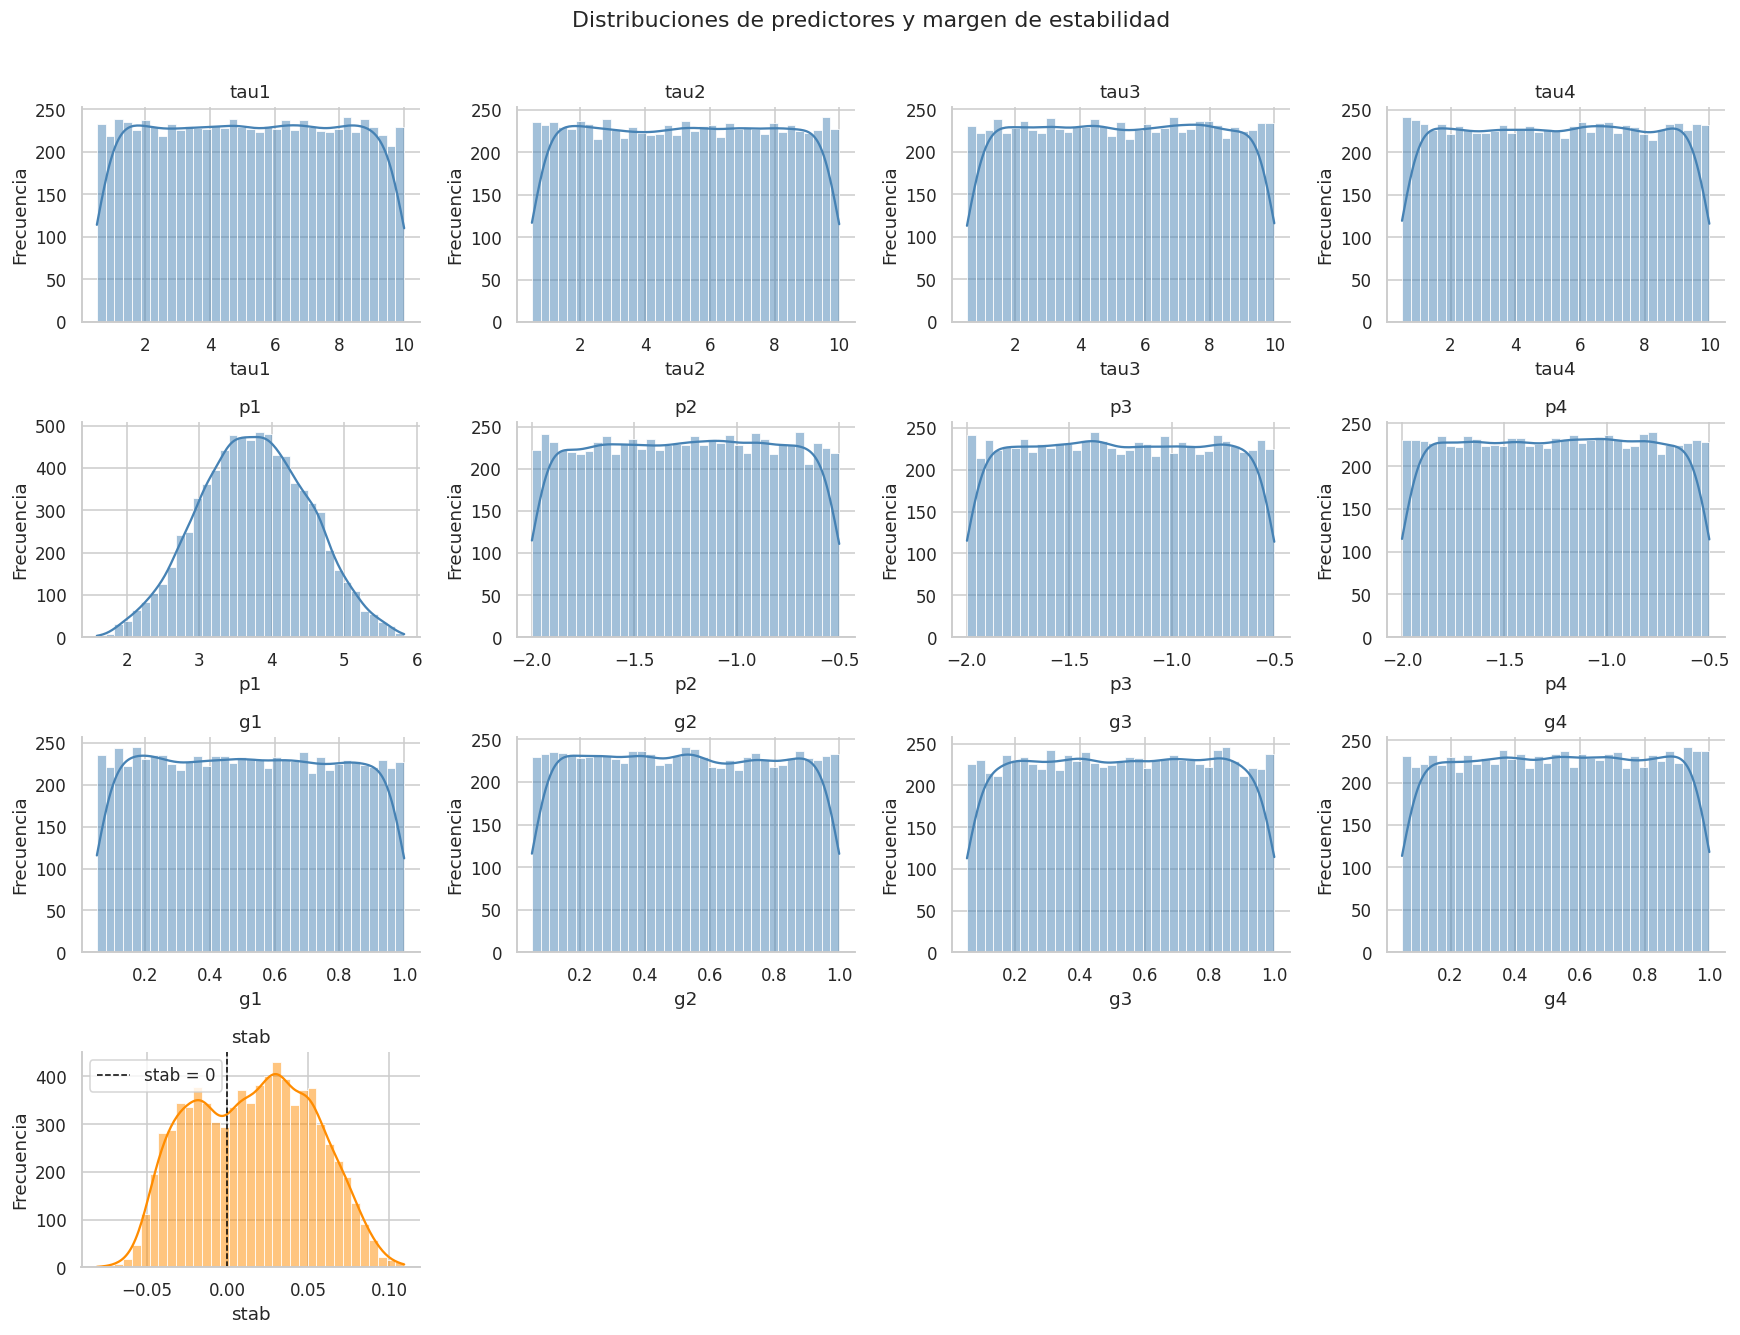

In [8]:
# Histogramas de todas las variables; KDE es una estimación suavizada.
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for ax, col in zip(axes.flat, datos.columns):
    sns.histplot(
        data=datos,
        x=col,
        bins=35,
        kde=True,
        ax=ax,
        color='darkorange' if col == OBJETIVO else 'steelblue'
    )

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')

    if col == OBJETIVO:
        ax.axvline(
            0,
            color='black',
            linestyle='--',
            linewidth=1,
            label=f'{OBJETIVO} = 0'
        )
        ax.legend()

# Ocultar paneles sobrantes
for ax in axes.flat[len(datos.columns):]:
    ax.set_visible(False)

fig.suptitle(
    'Distribuciones de predictores y margen de estabilidad',
    y=1.01
)

plt.tight_layout()
plt.show()


**Forma de las distribuciones**

Los histogramas de `tau`, `g` y las variables de consumo muestran distribuciones aproximadamente uniformes dentro de intervalos acotados, mientras que `p1` presenta una mayor concentración central, compatible con su construcción como suma de magnitudes de consumo.

Estas diferencias describen la distribución marginal de los predictores, pero no permiten inferir su relación con la variable objetivo ni justifican transformaciones por sí solas.

Por su parte, `stab` presenta indicios de multimodalidad, con varias concentraciones de observaciones que podrían reflejar distintos regímenes de estabilidad asociados con diferentes configuraciones de los parámetros de entrada. Aunque esto sugiere posible heterogeneidad en la respuesta, no demuestra relaciones no lineales. Por ello, se justifica evaluar modelos lineales y no lineales, determinando su conveniencia mediante validación cruzada y desempeño predictivo en el conjunto de prueba.


### Análisis de correlación

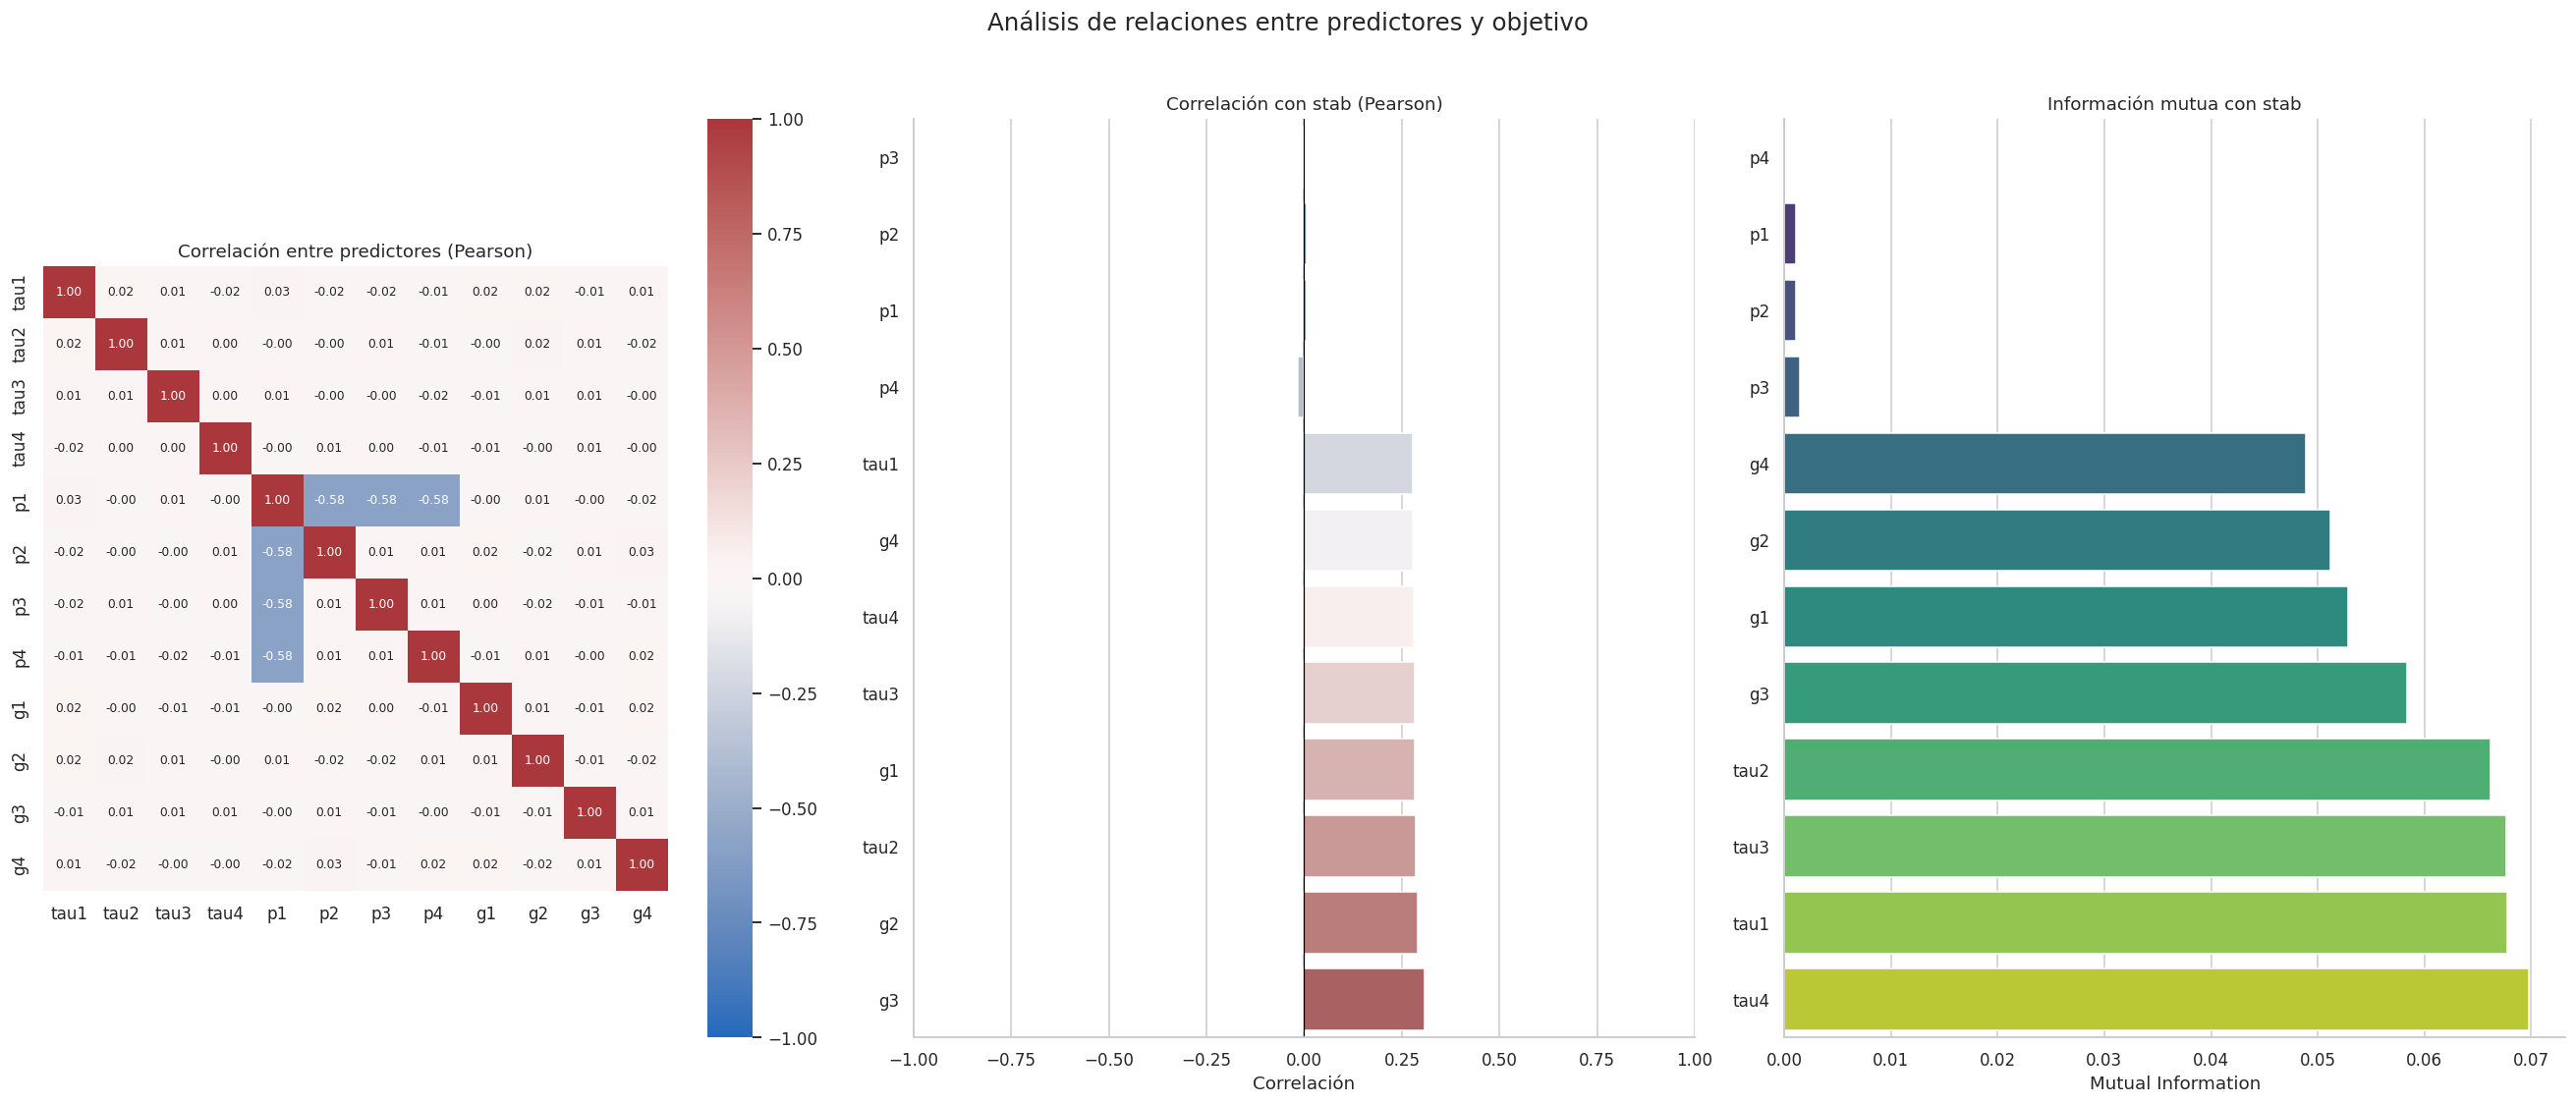

In [9]:
PREDICTORES = datos.columns.drop(OBJETIVO).tolist()

# Correlación de Pearson
corr_pearson = datos.corr(method='pearson')

corr_x = corr_pearson.loc[PREDICTORES, PREDICTORES]

# Pares de predictores más correlacionados
triangulo = np.triu(np.ones(corr_x.shape, dtype=bool), k=1)

pares_correlacionados = (
    corr_x.where(triangulo)
    .stack()
    .rename('Pearson')
)

# Correlación de predictores con el objetivo
corr_objetivo = (
    corr_pearson.loc[PREDICTORES, OBJETIVO]
    .sort_values(key=lambda s: s.abs(), ascending=True)
)

# Información mutua descriptiva en nats; no se usa como selector previo a CV.
mi = pd.Series(
    mutual_info_regression(
        datos[PREDICTORES],
        datos[OBJETIVO],
        random_state=42,
        n_neighbors=100
    ),
    index=PREDICTORES,
    name='Mutual Information'
).sort_values()

# Visualizaciones: tres columnas
fig, axes = plt.subplots(1, 3, figsize=(24, 10))

# Primera columna: correlación entre predictores
sns.heatmap(
    corr_x,
    vmin=-1, vmax=1, center=0,
    cmap='vlag',
    annot=True, fmt='.2f',
    annot_kws={'size': 8},
    square=True,
    ax=axes[0]
)
axes[0].set_title('Correlación entre predictores (Pearson)')

# Segunda columna: correlación con objetivo
sns.barplot(
    x=corr_objetivo.values,
    y=corr_objetivo.index,
    hue=corr_objetivo.index,
    palette='vlag',
    legend=False,
    ax=axes[1]
)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlim(-1, 1)
axes[1].set_title(f'Correlación con {OBJETIVO} (Pearson)')
axes[1].set_xlabel('Correlación')
axes[1].set_ylabel('')

# Tercera columna: información mutua
sns.barplot(
    x=mi.values,
    y=mi.index,
    hue=mi.index,
    palette='viridis',
    legend=False,
    ax=axes[2]
)
axes[2].set_title(f'Información mutua con {OBJETIVO}')
axes[2].set_xlabel('Mutual Information')
axes[2].set_ylabel('')

fig.suptitle('Análisis de relaciones entre predictores y objetivo', fontsize=16, y=1.02)

plt.tight_layout()
plt.show()


**Redundancia entre potencias**

Las correlaciones de `p1` con `p2`, `p3` y `p4` están entre aproximadamente −0.579 y −0.585, lo que evidencia asociaciones lineales negativas moderadas. Sin embargo, las correlaciones por pares no permiten caracterizar completamente la dependencia conjunta entre estas variables. En este caso, se cuenta con una restricción algebraica derivada del sistema físico: **`p1+p2+p3+p4=0`**. Por lo tanto, se excluye `p1` de las familias lineales y polinomiales por esta restricción física. No es obligatorio calcular VIF para justificar una redundancia algebraica conocida. Con `alpha>0`, Ridge puede ajustarse aun con dependencia exacta: retirar `p1` fija una parametrización distinta y modifica la penalización L2, por lo que esa base se mantendrá fija durante CV. Las correlaciones pequeñas entre las columnas restantes no demuestran independencia estadística ni determinan por sí solas su utilidad predictiva.

**Asociación lineal con `stab`**

Las mayores correlaciones de Pearson con stab corresponden a `g3` (0.309), `g2` (0.291) y `tau2` (0.286). Estas correlaciones positivas indican que, marginalmente, mayores valores de estas variables tienden a asociarse con valores más altos de stab, lo que representa una disminución de la estabilidad.

En términos de magnitud, estas asociaciones son moderadas-bajas. Por ejemplo, `g3` presenta un $r^2 \approx 0.0957$, lo que significa que una regresión lineal simple con intercepto explica aproximadamente el 9.57% de la variabilidad observada de stab en la muestra. Esto evidencia que ninguna de estas variables, considerada individualmente, captura una proporción elevada de la variabilidad del objetivo.

Por otra parte, las potencias presentan correlaciones prácticamente nulas con stab $(|r| menor que 0.017)$, lo que indica una asociación lineal marginal muy débil. Sin embargo, esto no implica que carezcan de información predictiva, ya que podrían intervenir mediante relaciones no lineales o interacciones con otras variables.

**Información mutua (MI)**

Las estimaciones de información mutua (MI), calculadas con 100 vecinos, muestran que las variables `tau` presentan la mayor dependencia con `stab`, seguidas de las variables `g`, mientras que las potencias registran valores considerablemente menores. Esto sugiere que `tau` y `g` contienen mayor información estadística individual sobre el objetivo. A diferencia de Pearson, MI permite detectar dependencias tanto lineales como no lineales, identificando posibles asociaciones que la correlación convencional no captura.



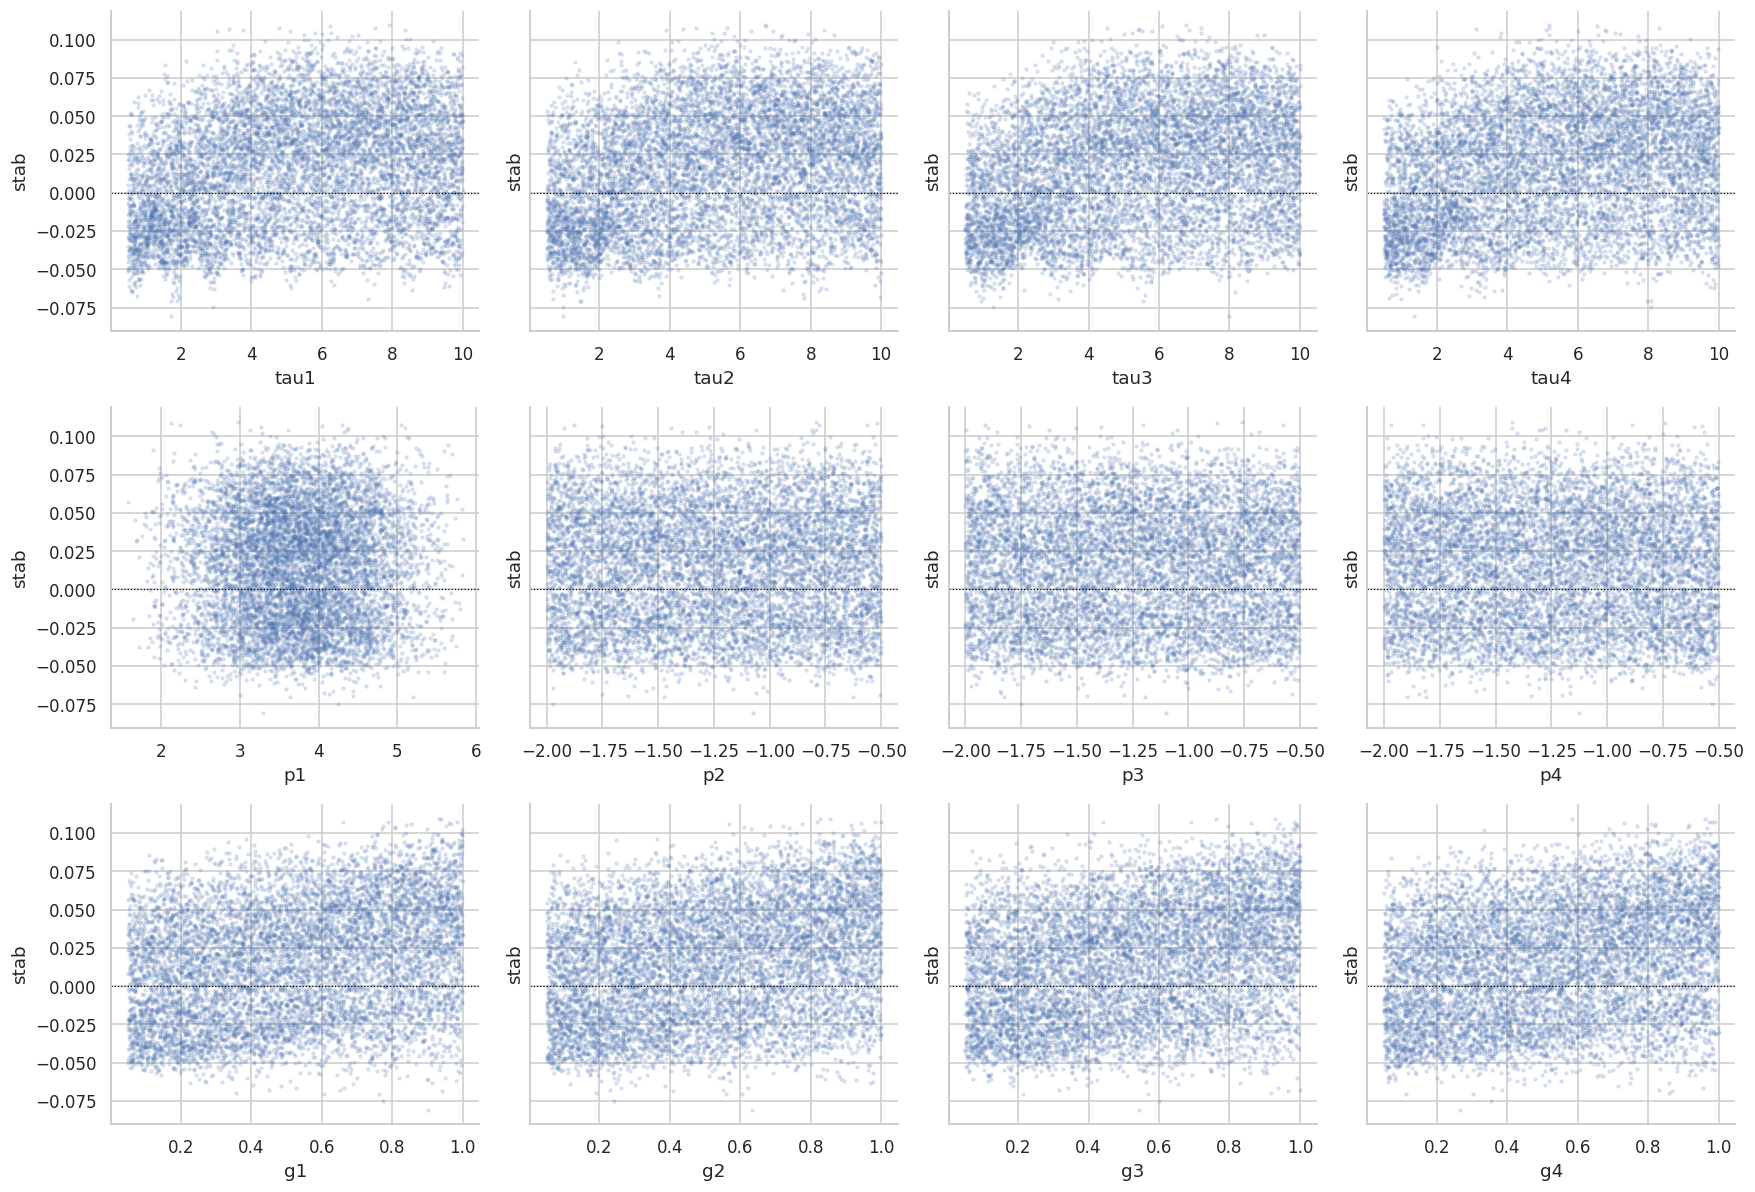

In [10]:
# Asociaciones marginales; la envolvente no estima la media condicional ni efectos parciales.
fig, axes = plt.subplots(3, 4, figsize=(16, 11), sharey=True)
for ax, col in zip(axes.flat, PREDICTORES):
    ax.scatter(datos[col], datos[OBJETIVO], s=4, alpha=0.15, rasterized=True)
    ax.axhline(0, color='black', linestyle=':', linewidth=0.8)
    ax.set(xlabel=col, ylabel='stab')
plt.tight_layout()
plt.show()


**Relaciones marginales y especificación del modelo**

El análisis visual de las relaciones entre los predictores y stab permite identificar patrones de asociación potencialmente lineales y no lineales. Las variables `tau` muestran cambios en la estructura de las nubes y un aplanamiento progresivo de su envolvente, lo que sugiere posibles efectos no lineales. Las variables `g` presentan una tendencia positiva, mientras que las potencias no muestran patrones marginales definidos. Estos comportamientos orientan la selección de especificaciones para los modelos; sin embargo, deben validarse empíricamente mediante comparación de modelos y validación cruzada, ya que la inspección visual no demuestra una mejora predictiva al incorporar términos cuadráticos o interacciones.



## **Preprocesamiento**

### Evidencia del análisis exploratorio y decisiones de modelado

1\. Calidad de los datos

- No se identificaron valores faltantes, infinitos ni registros duplicados.
- Se conservaron las 8,000 observaciones originales, sin requerir imputación ni eliminación de registros.

2\. Análisis de valores atípicos

- Se identificó una observación de `p1` por debajo del límite inferior de la cerca IQR. Se decidió conservarla por su consistencia física; la regla IQR por sí sola no determina error o influencia.

3\. Escala de los predictores

- Se observó una diferencia de escala aproximada de 10:1 entre `tau` y `g`.
- Se fija `StandardScaler` en OLS, polinomios y SVR. En SVR iguala la escala de las entradas para calcular distancias; en Ridge fija la escala sobre la que actúa la penalización L2. En OLS facilita interpretar asociaciones parciales por una desviación estándar y puede mejorar el acondicionamiento. El árbol se mantiene sin escalado.

4\. Forma de las distribuciones

- Las variables presentan asimetrías pequeñas e histogramas acotados.
- Se mantendrá la parametrización física sin transformaciones logarítmicas ni por cuantiles. Los cambios afines de escala previstos en los pipelines no buscan imponer gaussianidad ni descartar observaciones.

5\. Colinealidad y restricciones físicas

- Se identificó un balance físico y un diseño lineal mal condicionado asociado con `p1`.
- Se excluirá esta variable de OLS y de los modelos polinomiales. Para Ridge, se conservará la especificación de la base y se seleccionará el parámetro de regularización `alpha` mediante validación cruzada.

6\. Relevancia de los términos de mayor orden

- Las potencias `p2`–`p4` presentan asociaciones marginales pequeñas, tanto en correlación de Pearson como en información mutua.
- Se conservarán como candidatos, dado que una baja asociación marginal no implica necesariamente ausencia de relevancia condicional. En esta especificación no se implementa un selector supervisado: se mantienen los doce predictores, retirando solo `p1` dentro de las familias indicadas por el balance físico. Cualquier selección supervisada adicional requeriría aprenderse en los folds internos.

7\. Expansión polinomial

- La expansión genera monomios con escalas y dispersiones diferentes.
- Se estandarizarán los términos polinomiales antes de aplicar Ridge, de modo que la penalización sea comparable entre coeficientes. El grado de expansión y la intensidad de regularización se determinarán mediante validación cruzada.

8\. Variable objetivo

- Se conservará en su escala original, sin transformaciones, y las métricas RMSE y MAE, así como el parámetro `epsilon` de SVR, se expresarán en las unidades originales de `stab`.

### Protocolo de validación anidada: 5 externos × 5 internos

`X` e `y` se obtienen exclusivamente de los datos de entrenamiento. No se crea un hold-out adicional. Se asumen simulaciones independientes; la ausencia de duplicados no demuestra esa independencia. Cinco folds externos comunes estiman el desempeño de cada procedimiento; dentro de cada entrenamiento externo, otros cinco folds seleccionan los hiperparámetros con `StandardScaler` fijo en los modelos indicados. `cross_validate` recibe el `GridSearchCV` completo sin ajustar previamente. Cada observación recibe una predicción externa OOF de un procedimiento que no utilizó su respuesta para ajustar ni seleccionar.

Las medias y desviaciones utilizadas por `StandardScaler` se aprenden **solo en el entrenamiento de cada fold**, mediante los pipelines. La validación y la prueba usan esos parámetros sin reestimarlos. Las cinco métricas externas por familia producen sus medias y desviaciones estándar (`ddof=0`). Los prefijos `test_` de `cross_validate` indican validación externa de train, no el CSV de prueba. La puntuación interna ganadora sirve para seleccionar; no sustituye la evaluación externa.

Seleccionar la familia con el menor RMSE externo puede introducir optimismo adicional por selección entre familias; el CSV test se reserva para la evaluación posterior. Después de comparar se fijan los hiperparámetros a partir de las combinaciones ganadoras de los cinco bucles internos: se utiliza la combinación completa más frecuente; los empates se resuelven con el menor RMSE interno medio de esa misma combinación en los cinco bucles internos. Con esos parámetros fijos se ajusta un pipeline por familia con todo train, sin una nueva búsqueda. Las métricas externas evalúan el procedimiento de selección por fold; el CSV test evaluará los pipelines finales obtenidos por esta regla de consenso. Las desviaciones entre folds describen dispersión, no intervalos de confianza ni réplicas independientes.


In [6]:
# Preparar train sin ajustar escaladores ni seleccionar variables con la respuesta.
PREDICTORES = ([f'tau{i}' for i in range(1, 5)]
               + [f'p{i}' for i in range(1, 5)]
               + [f'g{i}' for i in range(1, 5)])
PREDICTORES_SIN_P1 = [col for col in PREDICTORES if col != 'p1']
TOLERANCIA_BALANCE = 1e-7  # Tolerancia absoluta en unidades de potencia; redondeo observado ~1e-9.


def validar_tabla(tabla, exigir_objetivo=True):
    """Validar esquema y dominio sin imputar, recortar ni eliminar filas."""
    if tabla.empty:
        raise ValueError('El CSV no contiene observaciones.')
    requeridas = PREDICTORES + ([OBJETIVO] if exigir_objetivo else [])
    faltantes = sorted(set(requeridas) - set(tabla.columns))
    if faltantes:
        raise ValueError(f'Faltan columnas requeridas: {faltantes}')
    columnas = PREDICTORES + ([OBJETIVO] if OBJETIVO in tabla.columns else [])
    numericas = tabla.loc[:, columnas].apply(pd.to_numeric, errors='raise').astype(float)
    if not np.isfinite(numericas.to_numpy()).all():
        raise ValueError('Revisar valores faltantes o infinitos antes de entrenar o predecir.')
    extras = sorted(set(tabla.columns) - set(columnas))
    if extras:
        print('Columnas adicionales excluidas de los modelos:', extras)

    # No usar los extremos observados de train como umbrales de recorte del test.
    balance = numericas[['p1', 'p2', 'p3', 'p4']].sum(axis=1)
    incumplimientos = {
        'tiempos_no_positivos': int((numericas[[f'tau{i}' for i in range(1, 5)]] <= 0).sum().sum()),
        'produccion_no_positiva': int((numericas['p1'] <= 0).sum()),
        'consumos_no_negativos': int((numericas[['p2', 'p3', 'p4']] >= 0).sum().sum()),
        'elasticidades_negativas': int((numericas[[f'g{i}' for i in range(1, 5)]] < 0).sum().sum()),
        'balance_inconsistente': int((balance.abs() > TOLERANCIA_BALANCE).sum()),
    }
    if any(incumplimientos.values()):
        raise ValueError(f'Revisar inconsistencias físicas; no se eliminan automáticamente: {incumplimientos}')
    return numericas


datos_modelado = validar_tabla(datos, exigir_objetivo=True)
X = datos_modelado.loc[:, PREDICTORES].copy()
y = datos_modelado.loc[:, OBJETIVO].copy()
assert OBJETIVO not in X.columns and X.index.equals(y.index)
assert len(X) == len(datos)  # Se conservan todas las filas del CSV proporcionado.
assert X.nunique().gt(1).all(), 'Revisar predictores constantes antes de continuar.'
assert N_EXTERNOS == N_INTERNOS == 5
print(f'X: {X.shape}; y: {y.shape}.')
print(f'Máximo residuo absoluto de balance: {X[["p1", "p2", "p3", "p4"]].sum(axis=1).abs().max():.3e}')


X: (8000, 12); y: (8000,).
Máximo residuo absoluto de balance: 1.000e-09


## **Entrenamiento y evaluación con validación cruzada anidada**

**Espacios de búsqueda exhaustiva**

Las cinco familias utilizan **`GridSearchCV`** dentro de la validación anidada 5×5. `StandardScaler` está fijo en OLS, polinomios y SVR; el árbol no se escala. Sus medias y desviaciones se estiman de nuevo en cada fold, junto con el resto del pipeline.

| Familia | Candidatos por búsqueda interna | Espacio explorado |
|---|---:|---|
| Regresión lineal | **1** | OLS con intercepto; sin hiperparámetros de complejidad. |
| Polinomial sin regularización | **2** | Grados **2 y 3**, con todos los términos e interacciones de grado total hasta el grado elegido; OLS sin penalización. |
| Polinomial Ridge | **20** | Grados {2,3}; `alpha` en **{10⁻⁴,10⁻³,10⁻²,10⁻¹,1,10,10²,10³,10⁴,10⁵}**; términos estandarizados. |
| SVR RBF | **18** | `C` en **{0.1,1,10}**, `epsilon` en **{0.001,0.005,0.01}** y `gamma` en **{0.01,0.1}**, con entradas estandarizadas. |
| Árbol de regresión | **16** | **Prepoda:** `max_depth` en {4,8,12,None}, `min_samples_leaf` en {1,5,20} y `ccp_alpha=0` (12 combinaciones). **Poda por complejidad:** `max_depth=None`, `min_samples_leaf=1` y `ccp_alpha` en {10⁻⁷,10⁻⁶,10⁻⁵,10⁻⁴} (4 combinaciones). |

**Grado y regularización:** Los grados 2 y 3 generan **77 y 363 términos** con las once entradas sin `p1`. Ambos se evalúan exhaustivamente. La malla de `alpha` contiene diez potencias de diez entre 10⁻⁴ y 10⁵, abarcando nueve décadas. Contrasta penalización débil y fuerte sobre una base de monomios estandarizada y fija; su efecto también depende del tamaño muestral y de las correlaciones entre términos.

**SVR:** Los tres valores de `epsilon` se expresan en unidades de `stab` y contrastan distintas tolerancias. Se exploran tres niveles de penalización `C` y dos alcances del kernel mediante `gamma`. Como la representación está fijada por `StandardScaler`, no se necesitan mallas de gamma para otros escaladores. Las **3 C × 3 epsilon × 2 gamma = 18** combinaciones ajustan los tres hiperparámetros principales sin modificar el objetivo ni consultar la prueba.

**Control del sobreajuste del árbol:** La profundidad y el tamaño mínimo de hoja limitan la complejidad antes de podar; `ccp_alpha` penaliza el número de hojas. El árbol libre (`None`, 1, 0) es una referencia, no una elección anticipada. La malla condicional compara prepoda y poda por complejidad por separado; no explora todas sus interacciones. La selección minimiza RMSE interno y se evalúa externamente, junto con el error de entrenamiento.

**Presupuesto y alcance:** Las mallas contienen **57 candidatos** en total: **1,450 ajustes** para la validación anidada, incluidos sus refits, y **5 ajustes finales directos**, uno por familia; total **1,455 ajustes previstos**. El ajuste final reutiliza hiperparámetros ganadores de la CV anidada y no vuelve a explorar las mallas. Se mantienen los cinco modelos y la CV 5×5. Se selecciona la mejor combinación evaluada, sin garantizar un óptimo global fuera de las mallas.

In [8]:
def metricas_regresion(y_real, prediccion):
    # La raíz del MSE evita depender del argumento squared de versiones antiguas.
    return {
        'RMSE': float(np.sqrt(mean_squared_error(y_real, prediccion))),
        'MAE': float(mean_absolute_error(y_real, prediccion)),
        'R2': float(r2_score(y_real, prediccion)),
    }


def convertir_json(valor):
    # Convertir estructuras de numpy y parámetros de sklearn a metadatos legibles.
    if isinstance(valor, dict):
        return {str(k): convertir_json(v) for k, v in valor.items()}
    if isinstance(valor, (list, tuple)):
        return [convertir_json(v) for v in valor]
    if isinstance(valor, np.ndarray):
        return convertir_json(valor.tolist())
    if isinstance(valor, np.generic):
        return valor.item()
    if isinstance(valor, BaseEstimator):
        return {'clase': type(valor).__name__, 'parametros': convertir_json(valor.get_params(deep=False))}
    if isinstance(valor, Path):
        return str(valor)
    if valor is None or isinstance(valor, (str, int, float, bool)):
        return valor
    return repr(valor)


def guardar_json(ruta, contenido):
    ruta.write_text(json.dumps(convertir_json(contenido), ensure_ascii=False,
                               indent=2, allow_nan=False), encoding='utf-8')



def describir_escaladores(pipeline):
    # Hiperparámetros del escalado; los estadísticos aprendidos se conservan en el .joblib.
    return {
        nombre: {'clase': type(paso).__name__, 'parametros': paso.get_params(deep=False)}
        for nombre, paso in pipeline.named_steps.items()
        if isinstance(paso, StandardScaler)
    }


def cargar_resultados_cv_guardados(ruta_resultados):
    """Recuperar la CV persistida; esta función no ejecuta búsquedas ni entrena."""
    ruta_resultados = Path(ruta_resultados)
    nombres = [
        'metricas_pliegues_externos.csv',
        'busquedas_internas_anidadas.csv',
        'comparacion_cv_anidada.csv',
    ]
    faltantes = [nombre for nombre in nombres if not (ruta_resultados / nombre).is_file()]
    if faltantes:
        raise FileNotFoundError(
            f'Faltan resultados de CV en {ruta_resultados}: {faltantes}. '
            'Copiar los CSV de la ejecución previa a esta carpeta. '
            'La carga no recalcula la CV automáticamente.'
        )
    externos = pd.read_csv(ruta_resultados / nombres[0])
    internos = pd.read_csv(ruta_resultados / nombres[1])
    comparativa = pd.read_csv(ruta_resultados / nombres[2]).set_index('modelo')

    requeridas = {
        'externos': {'modelo', 'pliegue_externo', 'hiperparametros', 'n_ajuste', 'n_validacion',
                     'RMSE', 'MAE', 'R2', 'RMSE_entrenamiento'},
        'internos': {'modelo', 'pliegue_externo', 'hiperparametros',
                     'RMSE_interno_media', 'RMSE_entrenamiento_interno'},
        'comparativa': {'familia', 'RMSE_CV_anidada', 'RMSE_sd', 'MAE_CV_anidada',
                        'MAE_sd', 'R2_CV_anidada', 'R2_sd', 'RMSE_entrenamiento_externo'},
    }
    for nombre, tabla in [('externos', externos), ('internos', internos), ('comparativa', comparativa)]:
        if tabla.empty or not requeridas[nombre].issubset(tabla.columns):
            raise ValueError(f'Resultados {nombre} incompletos: revisar columnas y filas guardadas.')
    familias = set(MODELOS)
    if (set(externos['modelo']) != familias or set(internos['modelo']) != familias
            or set(comparativa.index) != familias or not comparativa.index.is_unique):
        raise ValueError('Los CSV deben corresponder a las cinco familias definidas en MODELOS.')

    # Canonizar JSON permite comparar combinaciones completas y conserva None/int/float.
    for tabla in [externos, internos]:
        tabla['hiperparametros'] = tabla['hiperparametros'].map(
            lambda texto: json.dumps(json.loads(texto), ensure_ascii=False, sort_keys=True)
        )
        if not tabla['pliegue_externo'].isin(range(1, N_EXTERNOS + 1)).all():
            raise ValueError('Se esperaban los cinco folds externos numerados del 1 al 5.')
        tabla['pliegue_externo'] = tabla['pliegue_externo'].astype(int)
    if externos.duplicated(['modelo', 'pliegue_externo']).any():
        raise ValueError('Hay evaluaciones externas duplicadas.')
    if internos.duplicated(['modelo', 'pliegue_externo', 'hiperparametros']).any():
        raise ValueError('Hay candidatos internos duplicados dentro de un mismo fold.')
    if not externos.groupby('modelo')['pliegue_externo'].nunique().eq(N_EXTERNOS).all():
        raise ValueError('Faltan folds externos de alguna familia.')
    columnas_externas = ['RMSE', 'MAE', 'R2', 'RMSE_entrenamiento', 'n_ajuste', 'n_validacion']
    columnas_internas = ['RMSE_interno_media', 'RMSE_entrenamiento_interno']
    columnas_comparativas = ['RMSE_CV_anidada', 'RMSE_sd', 'MAE_CV_anidada', 'MAE_sd',
                            'R2_CV_anidada', 'R2_sd', 'RMSE_entrenamiento_externo']
    for tabla, columnas in [(externos, columnas_externas), (internos, columnas_internas),
                            (comparativa, columnas_comparativas)]:
        if not np.isfinite(tabla.loc[:, columnas].to_numpy(dtype=float)).all():
            raise ValueError('Las métricas y los tamaños guardados deben ser finitos.')
    if (not (externos['n_ajuste'] + externos['n_validacion']).eq(len(X)).all()
            or not externos.groupby('modelo')['n_validacion'].sum().eq(len(X)).all()):
        raise ValueError('El tamaño de train no coincide con la evaluación externa guardada.')

    # Comprobar mallas y cobertura sin instanciar GridSearchCV ni realizar ningún fit.
    for clave, especificacion in MODELOS.items():
        candidatos = {
            json.dumps(convertir_json(params), ensure_ascii=False, sort_keys=True)
            for params in ParameterGrid(especificacion['espacio'])
        }
        for fold in range(1, N_EXTERNOS + 1):
            filas = internos.loc[internos['modelo'].eq(clave) & internos['pliegue_externo'].eq(fold)]
            ganador = externos.loc[externos['modelo'].eq(clave) & externos['pliegue_externo'].eq(fold),
                                  'hiperparametros'].iloc[0]
            if set(filas['hiperparametros']) != candidatos or ganador not in candidatos:
                raise ValueError(f'La malla guardada de {clave}, fold {fold}, no coincide con la actual.')
        filas_externas = externos.loc[externos['modelo'].eq(clave)]
        for metrica, col_media, col_sd in [
            ('RMSE', 'RMSE_CV_anidada', 'RMSE_sd'),
            ('MAE', 'MAE_CV_anidada', 'MAE_sd'),
            ('R2', 'R2_CV_anidada', 'R2_sd'),
        ]:
            valores = filas_externas[metrica].to_numpy(dtype=float)
            if not np.allclose(
                [comparativa.loc[clave, col_media], comparativa.loc[clave, col_sd]],
                [valores.mean(), valores.std(ddof=0)], rtol=1e-8, atol=1e-12,
            ):
                raise ValueError(f'La comparativa de {clave} no coincide con sus cinco métricas externas.')

    # El manifiesto previo acredita los datos; sus parámetros finales antiguos NO se reutilizan.
    ruta_manifest_previo = ruta_resultados / 'modelos' / 'manifest_modelos.json'
    if ruta_manifest_previo.is_file():
        previo = json.loads(ruta_manifest_previo.read_text(encoding='utf-8'))
        protocolo = previo.get('protocolo', {})
        if (previo.get('sha256_entrenamiento') != hashlib.sha256(RUTA_TRAIN.read_bytes()).hexdigest()
                or previo.get('n_observaciones_entrenamiento') != len(X)
                or previo.get('columnas_entrada') != PREDICTORES
                or previo.get('objetivo') != OBJETIVO):
            raise ValueError('El manifiesto previo no corresponde al CSV train y al esquema actuales.')
        esperados = {'pliegues_externos': N_EXTERNOS, 'pliegues_internos': N_INTERNOS,
                     'semilla_interna': SEMILLA_INTERNA, 'semilla_externa': SEMILLA_EXTERNA,
                     'criterio': SCORE}
        if any(protocolo.get(k) != v for k, v in esperados.items()):
            raise ValueError('El protocolo de CV guardado no coincide con las constantes actuales.')

    # Ordenar por la evaluación EXTERNA; no usar las métricas del ajuste final anterior.
    comparativa = comparativa.loc[list(MODELOS)].sort_values('RMSE_CV_anidada', kind='stable')
    print(f'CV guardada cargada desde: {ruta_resultados}')
    print(f'{len(externos)} evaluaciones externas y {len(internos)} candidatos internos; CV no recalculada.')
    return externos, internos, comparativa


In [9]:
# StandardScaler queda fijo en los pipelines; GridSearchCV clona y ajusta cada pipeline por fold.
def seleccionar_sin_p1():
    return ColumnTransformer(
        [('sin_p1', 'passthrough', PREDICTORES_SIN_P1)],
        remainder='drop',
    )


def pipeline_polinomial(estimador):
    return Pipeline([
        ('seleccion', seleccionar_sin_p1()),
        ('escala_entrada', StandardScaler()),
        ('poly', PolynomialFeatures(include_bias=False)),
        ('escala_monomios', StandardScaler()),
        ('modelo', estimador),
    ])


MODELOS = {
    'lineal': {
        'nombre': 'Regresión lineal',
        'tipo_busqueda': 'grid',
        'pipeline': Pipeline([
            ('seleccion', seleccionar_sin_p1()),
            # Pendientes por una DE del predictor; interpretación y acondicionamiento de OLS.
            ('escala', StandardScaler()),
            ('modelo', LinearRegression()),
        ]),
        'espacio': {},
    },
    'polinomial': {
        'nombre': 'Polinomial sin regularización',
        'tipo_busqueda': 'grid',
        'pipeline': pipeline_polinomial(LinearRegression()),
        'espacio': {'poly__degree': [2, 3]},
    },
    'polinomial_ridge': {
        'nombre': 'Polinomial Ridge',
        'tipo_busqueda': 'grid',
        'pipeline': pipeline_polinomial(Ridge(solver='cholesky')),
        'espacio': {
            'poly__degree': [2, 3],
            'modelo__alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 1e2, 1e3, 1e4, 1e5],
        },
    },
    'svr_rbf': {
        'nombre': 'SVR RBF',
        'tipo_busqueda': 'grid',
        'pipeline': Pipeline([
            ('escala', StandardScaler()),  # Fijo; media y DE se aprenden dentro del fold.
            ('modelo', SVR(kernel='rbf', cache_size=256)),
        ]),
        'espacio': {
            'modelo__C': [0.1, 1.0, 10.0],
            'modelo__epsilon': [0.001, 0.005, 0.01],
            'modelo__gamma': [0.01, 0.1],
        },
    },
    'arbol': {
        'nombre': 'Árbol de regresión',
        'tipo_busqueda': 'grid',
        'pipeline': Pipeline([('modelo', DecisionTreeRegressor(random_state=SEMILLA))]),
        'espacio': [
            {
                'modelo__max_depth': [4, 8, 12, None],
                'modelo__min_samples_leaf': [1, 5, 20],
                'modelo__ccp_alpha': [0.0],
            },
            {
                'modelo__max_depth': [None],
                'modelo__min_samples_leaf': [1],
                'modelo__ccp_alpha': [1e-7, 1e-6, 1e-5, 1e-4],
            },
        ],
    },
}


def crear_busqueda(especificacion, semilla, n_pliegues=N_INTERNOS):
    # Solo las particiones se barajan; se evalúan todos los candidatos de la malla.
    interno = KFold(n_splits=n_pliegues, shuffle=True, random_state=semilla)
    return GridSearchCV(
        estimator=clone(especificacion['pipeline']),
        param_grid=especificacion['espacio'],
        scoring=SCORE,
        cv=interno,
        refit=True,
        return_train_score=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        error_score='raise',
    )


def numero_candidatos(especificacion):
    # ParameterGrid suma las ramas de las mallas condicionales sin cruzarlas entre sí.
    return len(ParameterGrid(especificacion['espacio']))


coste_busqueda = pd.DataFrame([
    {'modelo': clave, 'metodo': spec['tipo_busqueda'],
     'configuraciones': numero_candidatos(spec),
     'ajustes_anidados': N_EXTERNOS * (N_INTERNOS * numero_candidatos(spec) + 1),
     'ajustes_finales_directos': 1}
    for clave, spec in MODELOS.items()
])
display(coste_busqueda)
print('Total de ajustes previstos:', coste_busqueda[['ajustes_anidados', 'ajustes_finales_directos']].to_numpy().sum())
print('Términos polinomiales:', {g: math.comb(len(PREDICTORES_SIN_P1) + g, g) - 1 for g in [2, 3]})


,modelo,metodo,configuraciones,ajustes_anidados,ajustes_finales_directos
0,lineal,grid,1,30,1
1,polinomial,grid,2,55,1
2,polinomial_ridge,grid,20,505,1
3,svr_rbf,grid,18,455,1
4,arbol,grid,16,405,1


Total de ajustes previstos: 1455
Términos polinomiales: {2: 77, 3: 363}


In [14]:
# Los cinco resultados EXTERNOS de cada familia evalúan selección + preprocesamiento + ajuste.
# Los folds internos eligen hiperparámetros; sus puntuaciones no sustituyen a las externas.
# Los dos niveles usan cinco folds, aplicados únicamente al CSV train.
externo = KFold(n_splits=N_EXTERNOS, shuffle=True, random_state=SEMILLA_EXTERNA)
pliegues_externos = list(externo.split(X, y))
fold_por_fila = np.zeros(len(X), dtype=int)
cobertura_externa = np.zeros(len(X), dtype=int)
for numero, (indices_ajuste, indices_validacion) in enumerate(pliegues_externos, start=1):
    assert np.intersect1d(indices_ajuste, indices_validacion).size == 0, 'Fuga entre ajuste y validación externos.'
    assert len(indices_ajuste) + len(indices_validacion) == len(X)
    fold_por_fila[indices_validacion] = numero
    cobertura_externa[indices_validacion] += 1
assert np.all(cobertura_externa == 1), 'Cada observación debe validarse exactamente una vez.'


def resumir_busqueda(busqueda):
    # Esta tabla describe CV INTERNA; no representa evaluación independiente.
    resultado = pd.DataFrame(busqueda.cv_results_)
    return pd.DataFrame({
        'hiperparametros': [json.dumps(convertir_json(p), ensure_ascii=False, sort_keys=True) for p in resultado['params']],
        'RMSE_interno_media': -resultado['mean_test_score'],
        'RMSE_interno_sd': resultado['std_test_score'],
        'RMSE_entrenamiento_interno': -resultado['mean_train_score'],
        'rango_interno': resultado['rank_test_score'],
        'segundos_ajuste_medio': resultado['mean_fit_time'],
    })


RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
registros_externos = []
registros_internos = []
predicciones_oof = pd.DataFrame({'fila': np.arange(len(X)), 'pliegue_externo': fold_por_fila,
                                'stab_real': y.to_numpy()})

for clave, especificacion in MODELOS.items():
    print(f"\nFamilia: {especificacion['nombre']}", flush=True)
    # Evaluar el GridSearchCV completo en cinco folds externos, con varias métricas.
    busqueda = crear_busqueda(especificacion, semilla=SEMILLA_INTERNA)
    with parallel_backend('loky', inner_max_num_threads=1), threadpool_limits(limits=1):
        resultado_cv = cross_validate(
            estimator=busqueda,
            X=X,
            y=y,
            cv=externo,
            scoring=METRICAS_CV,
            return_train_score=True,
            return_estimator=True,
            n_jobs=1,  # Evitar paralelizar ambos niveles de la validación anidada.
            error_score='raise',
            verbose=2,
        )
    assert len(resultado_cv['estimator']) == N_EXTERNOS
    oof = np.full(len(X), np.nan)

    # Recuperar resultados de los cinco modelos YA entrenados por cross_validate.
    for i, ((idx_ajuste, idx_validacion), busqueda_pliegue) in enumerate(
            zip(pliegues_externos, resultado_cv['estimator'])):
        pliegue = i + 1
        pred_validacion = busqueda_pliegue.best_estimator_.predict(X.iloc[idx_validacion])
        oof[idx_validacion] = pred_validacion
        metricas = {
            'RMSE': -float(resultado_cv['test_RMSE'][i]),
            'MAE': -float(resultado_cv['test_MAE'][i]),
            'R2': float(resultado_cv['test_R2'][i]),
        }
        registros_externos.append({
            'modelo': clave, 'pliegue_externo': pliegue,
            'tipo_busqueda': type(busqueda_pliegue).__name__,
            'n_candidatos_evaluados': len(busqueda_pliegue.cv_results_['params']),
            'n_ajuste': len(idx_ajuste), 'n_validacion': len(idx_validacion),
            **metricas,
            'RMSE_entrenamiento': -float(resultado_cv['train_RMSE'][i]),
            'RMSE_mejor_interno': -float(busqueda_pliegue.best_score_),
            'segundos_ajuste': float(resultado_cv['fit_time'][i]),
            'hiperparametros': json.dumps(convertir_json(busqueda_pliegue.best_params_), ensure_ascii=False, sort_keys=True),
            'escaladores': json.dumps(convertir_json(describir_escaladores(busqueda_pliegue.best_estimator_)), ensure_ascii=False, sort_keys=True),
        })
        registros_internos.append(resumir_busqueda(busqueda_pliegue).assign(modelo=clave, pliegue_externo=pliegue))
        print(f"  Fold {pliegue}/{N_EXTERNOS}: RMSE={metricas['RMSE']:.6f}, "
              f"MAE={metricas['MAE']:.6f}, R²={metricas['R2']:.4f}; "
              f"parámetros={busqueda_pliegue.best_params_}", flush=True)

    # Resumen exactamente sobre las cinco puntuaciones externas de cada métrica.
    for metrica, signo in [('RMSE', -1), ('MAE', -1), ('R2', 1)]:
        puntajes = signo * np.asarray(resultado_cv[f'test_{metrica}'], dtype=float)
        assert puntajes.shape == (N_EXTERNOS,) and np.isfinite(puntajes).all()
        print(f"  {metrica}: media={puntajes.mean():.6f}; desviación estándar={puntajes.std(ddof=0):.6f}")

    assert np.isfinite(oof).all(), f'Predicciones OOF incompletas para {clave}.'
    predicciones_oof[f'pred_{clave}'] = oof

# Se guardan 5 familias × 5 folds y sus búsquedas internas, sin abrir el CSV test.
resultados_externos = pd.DataFrame(registros_externos)
assert len(resultados_externos) == len(MODELOS) * N_EXTERNOS
assert resultados_externos.groupby('modelo')['pliegue_externo'].nunique().eq(N_EXTERNOS).all()
resultados_internos = pd.concat(registros_internos, ignore_index=True)
resultados_externos.to_csv(RUTA_RESULTADOS / 'metricas_pliegues_externos.csv', index=False)
resultados_internos.to_csv(RUTA_RESULTADOS / 'busquedas_internas_anidadas.csv', index=False)
predicciones_oof.to_csv(RUTA_RESULTADOS / 'predicciones_oof.csv', index=False)
display(resultados_externos)



Familia: Regresión lineal
[CV] END .................................................... total time=   1.3s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   2.0s
  Fold 1/5: RMSE=0.021897, MAE=0.017346, R²=0.6438; parámetros={}
  Fold 2/5: RMSE=0.021755, MAE=0.017420, R²=0.6492; parámetros={}
  Fold 3/5: RMSE=0.021891, MAE=0.017272, R²=0.6423; parámetros={}
  Fold 4/5: RMSE=0.022309, MAE=0.017699, R²=0.6431; parámetros={}
  Fold 5/5: RMSE=0.022555, MAE=0.017915, R²=0.6341; parámetros={}
  RMSE: media=0.022081; desviación estándar=0.000301
  MAE: media=0.017531; desviación estándar=0.000241
  R2: media=0.642498; desviación estándar=0.004830

Familia: Polinomial sin regularización


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    9.5s finished


[CV] END .................................................... total time=   3.1s
[CV] END .................................................... total time=   1.6s
[CV] END .................................................... total time=   1.6s
[CV] END .................................................... total time=   1.6s
[CV] END .................................................... total time=   1.6s
  Fold 1/5: RMSE=0.009007, MAE=0.006236, R²=0.9397; parámetros={'poly__degree': 3}
  Fold 2/5: RMSE=0.008899, MAE=0.006180, R²=0.9413; parámetros={'poly__degree': 3}
  Fold 3/5: RMSE=0.008079, MAE=0.005720, R²=0.9513; parámetros={'poly__degree': 3}
  Fold 4/5: RMSE=0.008636, MAE=0.006049, R²=0.9465; parámetros={'poly__degree': 3}
  Fold 5/5: RMSE=0.008823, MAE=0.006296, R²=0.9440; parámetros={'poly__degree': 3}
  RMSE: media=0.008689; desviación estándar=0.000328
  MAE: media=0.006096; desviación estándar=0.000205
  R2: media=0.944569; desviación estándar=0.004078

Familia: Polinomial Rid

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    9.7s finished


[CV] END .................................................... total time=   4.4s
[CV] END .................................................... total time=   5.8s
[CV] END .................................................... total time=   5.8s
[CV] END .................................................... total time=   5.8s
[CV] END .................................................... total time=   5.8s
  Fold 1/5: RMSE=0.009008, MAE=0.006235, R²=0.9397; parámetros={'modelo__alpha': 1.0, 'poly__degree': 3}
  Fold 2/5: RMSE=0.008899, MAE=0.006178, R²=0.9413; parámetros={'modelo__alpha': 1.0, 'poly__degree': 3}
  Fold 3/5: RMSE=0.008077, MAE=0.005716, R²=0.9513; parámetros={'modelo__alpha': 1.0, 'poly__degree': 3}
  Fold 4/5: RMSE=0.008636, MAE=0.006047, R²=0.9465; parámetros={'modelo__alpha': 1.0, 'poly__degree': 3}
  Fold 5/5: RMSE=0.008823, MAE=0.006295, R²=0.9440; parámetros={'modelo__alpha': 0.1, 'poly__degree': 3}
  RMSE: media=0.008689; desviación estándar=0.000329
  MAE: media=0.00

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   27.9s finished


[CV] END .................................................... total time= 3.9min
[CV] END .................................................... total time= 3.8min
[CV] END .................................................... total time= 3.9min
[CV] END .................................................... total time= 3.8min
[CV] END .................................................... total time= 3.9min


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed: 19.4min finished


  Fold 1/5: RMSE=0.007835, MAE=0.005023, R²=0.9544; parámetros={'modelo__C': 0.1, 'modelo__epsilon': 0.001, 'modelo__gamma': 0.1}
  Fold 2/5: RMSE=0.007727, MAE=0.005023, R²=0.9557; parámetros={'modelo__C': 0.1, 'modelo__epsilon': 0.001, 'modelo__gamma': 0.1}
  Fold 3/5: RMSE=0.007332, MAE=0.004660, R²=0.9599; parámetros={'modelo__C': 0.1, 'modelo__epsilon': 0.001, 'modelo__gamma': 0.1}
  Fold 4/5: RMSE=0.007580, MAE=0.004979, R²=0.9588; parámetros={'modelo__C': 0.1, 'modelo__epsilon': 0.001, 'modelo__gamma': 0.1}
  Fold 5/5: RMSE=0.007565, MAE=0.004957, R²=0.9588; parámetros={'modelo__C': 0.1, 'modelo__epsilon': 0.001, 'modelo__gamma': 0.1}
  RMSE: media=0.007608; desviación estándar=0.000170
  MAE: media=0.004929; desviación estándar=0.000137
  R2: media=0.957528; desviación estándar=0.002090

Familia: Árbol de regresión
[CV] END .................................................... total time=   4.5s
[CV] END .................................................... total time=   4.5s
[CV

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   22.6s finished


,modelo,pliegue_externo,tipo_busqueda,n_candidatos_evaluados,n_ajuste,n_validacion,RMSE,MAE,R2,RMSE_entrenamiento,RMSE_mejor_interno,segundos_ajuste,hiperparametros,escaladores
0,lineal,1,GridSearchCV,1,6400,1600,0.021897,0.017346,0.643816,0.022095,0.022134,1.322841,{},"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std..."
1,lineal,2,GridSearchCV,1,6400,1600,0.021755,0.017420,0.649179,0.022130,0.022176,1.998617,{},"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std..."
2,lineal,3,GridSearchCV,1,6400,1600,0.021891,0.017272,0.642267,0.022098,0.022125,2.003830,{},"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std..."
3,lineal,4,GridSearchCV,1,6400,1600,0.022309,0.017699,0.643089,0.021990,0.022018,1.991887,{},"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std..."
4,lineal,5,GridSearchCV,1,6400,1600,0.022555,0.017915,0.634141,0.021928,0.021970,2.010360,{},"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std..."
5,polinomial,1,GridSearchCV,2,6400,1600,0.009007,0.006236,0.939736,0.007993,0.008686,3.050795,"{""poly__degree"": 3}","{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""..."
6,polinomial,2,GridSearchCV,2,6400,1600,0.008899,0.006180,0.941300,0.008044,0.008762,1.563998,"{""poly__degree"": 3}","{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""..."
7,polinomial,3,GridSearchCV,2,6400,1600,0.008079,0.005720,0.951279,0.008227,0.008948,1.589612,"{""poly__degree"": 3}","{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""..."
8,polinomial,4,GridSearchCV,2,6400,1600,0.008636,0.006049,0.946514,0.008083,0.008817,1.582941,"{""poly__degree"": 3}","{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""..."
9,polinomial,5,GridSearchCV,2,6400,1600,0.008823,0.006296,0.944017,0.008042,0.008783,1.598752,"{""poly__degree"": 3}","{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""..."


### Interpretación de la validación cruzada de cinco folds

**Consistencia de la selección** 

El polinomio sin regularización eligió grado **3 en los cinco folds**. Ridge también eligió grado **3 en todos**, con `alpha=1` en cuatro y `alpha=0.1` en uno. SVR seleccionó **C=0.1, epsilon=0.001 y gamma=0.1 en los cinco folds**; sus modelos ajustados siguen siendo distintos porque se entrenan con subconjuntos y estadísticas de escala diferentes. El árbol cambió entre profundidad 12/sin límite y hojas mínimas de 5/20, lo que muestra mayor sensibilidad de su configuración a la partición. Esta consistencia se limita a las mallas y semillas utilizadas.


## **Comparación de resultados**

La tabla contiene **una fila por cada una de las cinco familias**. El criterio principal es el **RMSE medio de validación externa**: menor es mejor. MAE complementa la magnitud del error y R² indica la fracción de variabilidad explicada (mayor es mejor; puede ser negativo). Para **cada modelo** se reportan **media y desviación estándar de RMSE, MAE y R² en los cinco folds externos del entrenamiento**. Las desviaciones describen la dispersión de esas cinco puntuaciones y **no son intervalos de confianza**.

`RMSE_OOF` se calcula juntando las predicciones externas de todas las filas. Puede diferir de la media de RMSE porque la raíz se aplica después de agregar los errores cuadrados. La brecha entre RMSE externo y de entrenamiento ayuda a describir el sobreajuste, pero no demuestra por sí sola sesgo o varianza. No se comparan familias usando la mejor puntuación interna.


,familia,RMSE_CV_anidada,RMSE_sd,MAE_CV_anidada,MAE_sd,R2_CV_anidada,R2_sd,RMSE_entrenamiento_externo,segundos_busquedas_externas,RMSE_OOF,brecha_RMSE
modelo,,,,,,,,,,,
svr_rbf,SVR RBF,0.007608,0.000170,0.004929,0.000137,0.957528,0.002090,0.004584,1152.395451,0.007610,0.003024
polinomial_ridge,Polinomial Ridge,0.008689,0.000329,0.006094,0.000206,0.944570,0.004090,0.008078,27.449201,0.008695,0.000611
polinomial,Polinomial sin regularización,0.008689,0.000328,0.006096,0.000205,0.944569,0.004078,0.008078,9.386097,0.008695,0.000611
arbol,Árbol de regresión,0.018490,0.000362,0.014404,0.000296,0.749266,0.008479,0.010184,22.519282,0.018493,0.008306
lineal,Regresión lineal,0.022081,0.000301,0.017531,0.000241,0.642498,0.004830,0.022048,9.327535,0.022084,0.000033


pliegue_externo,1,2,3,4,5
modelo,,,,,
svr_rbf,0.007835,0.007727,0.007332,0.007580,0.007565
polinomial_ridge,0.009008,0.008899,0.008077,0.008636,0.008823
polinomial,0.009007,0.008899,0.008079,0.008636,0.008823
arbol,0.018312,0.018038,0.018585,0.018393,0.019122
lineal,0.021897,0.021755,0.021891,0.022309,0.022555


Familia seleccionada por RMSE externo medio: SVR RBF


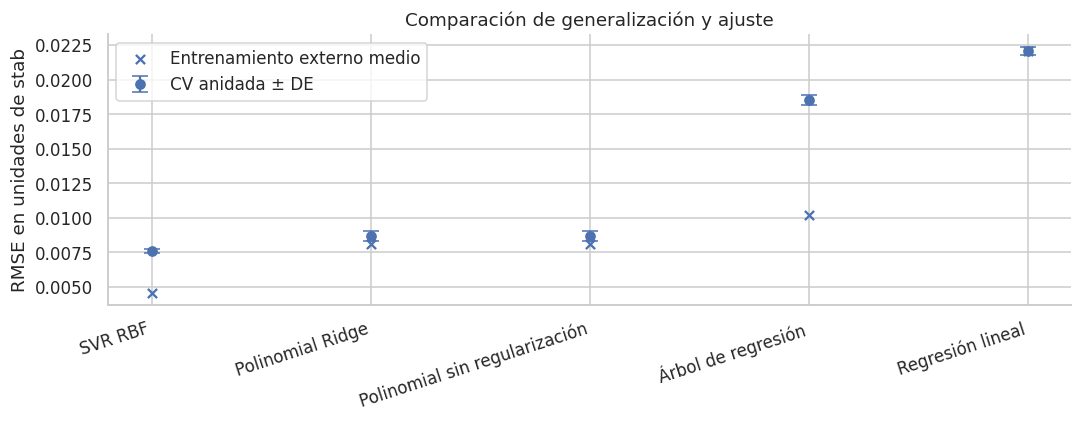

In [15]:
# La DE resume dispersión entre cinco folds; no es un intervalo de confianza del rendimiento.
# El primer lugar se decide por RMSE externo; MAE y R² complementan la comparación.
# Tabla comparativa: media y desviación estándar de cada métrica en los cinco folds.
def desviacion_cinco_folds(valores):
    return float(np.std(valores.to_numpy(), ddof=0))

# Ordenar únicamente por el RMSE externo medio del entrenamiento.
tabla_comparativa = resultados_externos.groupby('modelo', sort=False).agg(
    RMSE_CV_anidada=('RMSE', 'mean'),
    RMSE_sd=('RMSE', desviacion_cinco_folds),
    MAE_CV_anidada=('MAE', 'mean'),
    MAE_sd=('MAE', desviacion_cinco_folds),
    R2_CV_anidada=('R2', 'mean'),
    R2_sd=('R2', desviacion_cinco_folds),
    RMSE_entrenamiento_externo=('RMSE_entrenamiento', 'mean'),
    segundos_busquedas_externas=('segundos_ajuste', 'sum'),
)
for clave in MODELOS:
    tabla_comparativa.loc[clave, 'RMSE_OOF'] = metricas_regresion(
        y, predicciones_oof[f'pred_{clave}'])['RMSE']
tabla_comparativa['brecha_RMSE'] = (tabla_comparativa['RMSE_CV_anidada']
                                  - tabla_comparativa['RMSE_entrenamiento_externo'])
tabla_comparativa = tabla_comparativa.sort_values('RMSE_CV_anidada', kind='stable')
tabla_comparativa.insert(0, 'familia', [MODELOS[k]['nombre'] for k in tabla_comparativa.index])
tabla_comparativa.to_csv(RUTA_RESULTADOS / 'comparacion_cv_anidada.csv', index_label='modelo')
display(tabla_comparativa.round(6))

# Hacer visibles los cinco RMSE externos que sustentan media y desviación.
tabla_cinco_pliegues = resultados_externos.pivot(index='modelo', columns='pliegue_externo', values='RMSE')
display(tabla_cinco_pliegues.loc[tabla_comparativa.index].round(6))

# El ganador queda fijado ANTES del reajuste y de cualquier lectura del CSV test.
MEJOR_FAMILIA = tabla_comparativa.index[0]
segundo = tabla_comparativa.index[1]
print('Familia seleccionada por RMSE externo medio:', MODELOS[MEJOR_FAMILIA]['nombre'])

fig, ax = plt.subplots(figsize=(10, 4))
posiciones = np.arange(len(tabla_comparativa))
ax.errorbar(posiciones, tabla_comparativa['RMSE_CV_anidada'],
            yerr=tabla_comparativa['RMSE_sd'], fmt='o', capsize=5, label='CV anidada ± DE')
ax.scatter(posiciones, tabla_comparativa['RMSE_entrenamiento_externo'],
           marker='x', label='Entrenamiento externo medio')
ax.set_xticks(posiciones)
ax.set_xticklabels(tabla_comparativa['familia'], rotation=18, ha='right')
ax.set(ylabel='RMSE en unidades de stab', title='Comparación de generalización y ajuste')
ax.legend()
plt.tight_layout()
plt.show()


### Discusión de desempeño

La familia con menor RMSE externo medio es **SVR RBF**: **0.007608 ± 0.000170** (DE entre pliegues), MAE **0.004929 ± 0.000137** y R² **0.9575 ± 0.0021**.

Frente a **Polinomial Ridge**, reduce el RMSE medio en **0.001081** (12.44%). Tiene menor RMSE en **5/5** pliegues comunes. La DE de las diferencias pareadas es **0.000180**. Es una comparación descriptiva: los pliegues comparten datos de entrenamiento y no constituyen réplicas independientes.

- **SVR RBF**: RMSE externo 0.007608, entrenamiento 0.004584, brecha 0.003024; reducción frente a lineal +65.55%.

- **Polinomial Ridge**: RMSE externo 0.008689, entrenamiento 0.008078, brecha 0.000611; reducción frente a lineal +60.65%.

- **Polinomial sin regularización**: RMSE externo 0.008689, entrenamiento 0.008078, brecha 0.000611; reducción frente a lineal +60.65%.

- **Árbol de regresión**: RMSE externo 0.018490, entrenamiento 0.010184, brecha 0.008306; reducción frente a lineal +16.27%.

- **Regresión lineal**: RMSE externo 0.022081, entrenamiento 0.022048, brecha 0.000033; reducción frente a lineal +0.00%.

La familia seleccionada se confirma después en el CSV de prueba, sin volver a elegir familia ni hiperparámetros. Una diferencia pequeña frente a la variación entre pliegues aconseja cautela; no prueba superioridad estadística.

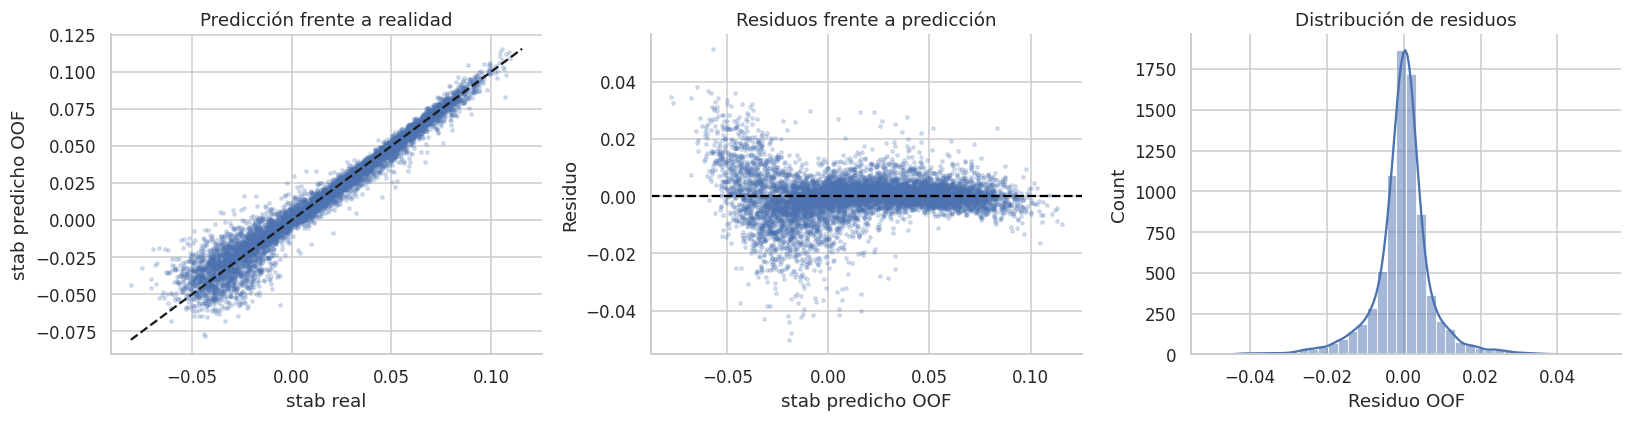

In [ ]:
# Interpretar brecha y error externo conjuntamente: una brecha mínima no garantiza buen modelo.
# Los residuos OOF combinan cinco ajustes; no son residuos del pipeline final entrenado con todo train.
# Redactar la discusión con los valores calculados; no asumir un ganador de antemano.
ganador = tabla_comparativa.loc[MEJOR_FAMILIA]
subcampeon = tabla_comparativa.loc[segundo]
rmse_por_pliegue = resultados_externos.pivot(index='pliegue_externo', columns='modelo', values='RMSE')
ventajas_pareadas = rmse_por_pliegue[segundo] - rmse_por_pliegue[MEJOR_FAMILIA]
diferencia = float(subcampeon['RMSE_CV_anidada'] - ganador['RMSE_CV_anidada'])
ventaja_porcentual = 100 * diferencia / subcampeon['RMSE_CV_anidada']
texto = [
    '### Discusión de desempeño',
    f"La familia con menor RMSE externo medio es **{ganador['familia']}**: "
    f"**{ganador['RMSE_CV_anidada']:.6f} ± {ganador['RMSE_sd']:.6f}** (DE entre pliegues), "
    f"MAE **{ganador['MAE_CV_anidada']:.6f} ± {ganador['MAE_sd']:.6f}** y "
    f"R² **{ganador['R2_CV_anidada']:.4f} ± {ganador['R2_sd']:.4f}**.",
    f"Frente a **{subcampeon['familia']}**, reduce el RMSE medio en **{diferencia:.6f}** "
    f"({ventaja_porcentual:.2f}%). Tiene menor RMSE en **{int((ventajas_pareadas > 0).sum())}/{N_EXTERNOS}** "
    f"pliegues comunes. La DE de las diferencias pareadas es **{ventajas_pareadas.std(ddof=0):.6f}**. "
    'Es una comparación descriptiva: los pliegues comparten datos de entrenamiento y no constituyen réplicas independientes.',
]
referencia_lineal = tabla_comparativa.loc['lineal', 'RMSE_CV_anidada']
for clave, fila in tabla_comparativa.iterrows():
    cambio = 100 * (referencia_lineal - fila['RMSE_CV_anidada']) / referencia_lineal
    texto.append(f"- **{fila['familia']}**: RMSE externo {fila['RMSE_CV_anidada']:.6f}, "
                 f"entrenamiento {fila['RMSE_entrenamiento_externo']:.6f}, "
                 f"brecha {fila['brecha_RMSE']:.6f}; reducción frente a lineal {cambio:+.2f}%.")
texto.append('La familia seleccionada se confirma después en el CSV de prueba, sin volver a elegir familia ni hiperparámetros. '
             'Una diferencia pequeña frente a la variación entre pliegues aconseja cautela; no prueba superioridad estadística.')
display(Markdown('\n\n'.join(texto)))

# Diagnóstico OOF del ganador: estos residuos provienen de validación, no de ajuste.
pred_ganador = predicciones_oof[f'pred_{MEJOR_FAMILIA}']
residuos_oof = y.to_numpy() - pred_ganador.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(y, pred_ganador, s=5, alpha=0.2)
limites = [min(y.min(), pred_ganador.min()), max(y.max(), pred_ganador.max())]
axes[0].plot(limites, limites, 'k--')
axes[0].set(xlabel='stab real', ylabel='stab predicho OOF', title='Predicción frente a realidad')
axes[1].scatter(pred_ganador, residuos_oof, s=5, alpha=0.2)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='stab predicho OOF', ylabel='Residuo', title='Residuos frente a predicción')
sns.histplot(residuos_oof, bins=40, kde=True, ax=axes[2])
axes[2].set(xlabel='Residuo OOF', title='Distribución de residuos')
plt.tight_layout()
plt.show()


**Conclusiones**

**1. Mejor desempeño predictivo: SVR con kernel RBF**

De las cinco familias evaluadas, **SVR con kernel RBF obtuvo el mejor desempeño predictivo**, al registrar el menor RMSE (0.007) y MAE (0.004), así como el mayor R² medio (0.957). Estos resultados indican que el modelo logra aproximaciones más precisas a los valores reales y explica una mayor proporción de su variabilidad respecto a las demás alternativas evaluadas.

Su ventaja frente a Polinomial Ridge, el segundo modelo en el ordenamiento, se mantiene en los cinco folds de validación, con una reducción promedio del RMSE de 0.001 (12.44%). Asimismo, presenta la menor desviación estándar del RMSE entre las cinco familias, lo que evidencia una menor variabilidad de su desempeño entre las particiones utilizadas. Aunque estos resultados respaldan su elección como mejor alternativa, no constituyen por sí mismos una prueba estadística de superioridad.

**2. Capacidad para representar relaciones no lineales**

El desempeño de SVR RBF y de los modelos polinomiales supera al de OLS, lo que sugiere que una especificación lineal aditiva resulta limitada para representar las relaciones entre las variables predictoras y la variable objetivo.

En particular, el kernel RBF permite modelar relaciones no lineales sin necesidad de especificar explícitamente términos polinomiales o interacciones entre variables. Su mejor desempeño sugiere que esta flexibilidad resulta favorable para los datos analizados. No obstante, la comparación no permite identificar la forma funcional verdadera de las relaciones ni atribuir efectos causales a las variables predictoras.

**3. Efecto de la regularización: comparación entre Ridge y Polinomial**

Los modelos Polinomial Ridge y Polinomial sin regularización presentan resultados prácticamente equivalentes en las métricas evaluadas: ambos registran un RMSE de 0.008, con valores de MAE y R² también muy similares.

Esto indica que, bajo la configuración experimental considerada, la incorporación de regularización L2 no produjo una mejora predictiva apreciable. Si bien Ridge puede ayudar a controlar la magnitud de los coeficientes y reducir el sobreajuste, sus beneficios no se reflejaron de manera significativa en el desempeño observado. Este resultado no implica que la regularización carezca de utilidad en otras muestras o especificaciones del modelo.

**4. Limitaciones de los modelos de menor desempeño**

OLS presentó el mayor error predictivo entre las cinco familias, mientras que el árbol de decisión obtuvo un desempeño intermedio, aunque inferior al de SVR RBF y los modelos polinomiales.

La mejora de los modelos polinomiales y SVR respecto a OLS es consistente con la presencia de patrones que no quedan suficientemente representados mediante una relación lineal aditiva. Por su parte, el desempeño del árbol muestra que la incorporación de no linealidad no garantiza, por sí sola, una mayor precisión: la capacidad de representación y la forma en que cada algoritmo aproxima las relaciones presentes en los datos también son determinantes.

**5. Análisis de residuos OOF de SVR RBF**

El análisis de los residuos *Out-of-Fold* confirma un buen comportamiento predictivo general, con una concentración importante de observaciones alrededor de la diagonal en el gráfico de valores predichos frente a reales y una proporción considerable de errores cercanos a cero.

Sin embargo, se observa una mayor dispersión de los residuos en la región de predicciones negativas, lo que sugiere que la precisión del modelo no es uniforme a lo largo del rango de la variable objetivo. Aunque el histograma muestra una concentración pronunciada alrededor de cero, también se identifican colas con errores de mayor magnitud.

Este comportamiento pone de manifiesto que las métricas globales no describen por completo las diferencias de desempeño entre regiones. En particular, resulta relevante estudiar las predicciones cercanas al umbral `stab = 0`, donde incluso errores de regresión pequeños pueden modificar el signo de la predicción y ocasionar una clasificación incorrecta de la estabilidad del sistema.

Por otra parte, dado que los residuos OOF combinan predicciones de cinco ajustes distintos, los patrones observados deben interpretarse como características del comportamiento predictivo del procedimiento de validación, y no como evidencia formal de heterocedasticidad en un único modelo final.

**6. Consideraciones finales**

En conjunto, los resultados favorecen la selección de SVR RBF como la alternativa con mejor desempeño predictivo entre las familias consideradas. Su menor error, mayor R² medio y menor variabilidad entre folds respaldan esta elección dentro del esquema experimental utilizado.

No obstante, la evaluación no debe limitarse a las métricas globales de regresión. Dado que el signo de `stab` permite distinguir entre condiciones de estabilidad e inestabilidad, resulta conveniente complementar el análisis con métricas de clasificación, una evaluación específica de las observaciones cercanas al umbral cero y el desempeño sobre un conjunto de prueba independiente.

De esta manera, será posible determinar no solamente qué modelo aproxima mejor los valores de estabilidad, sino también qué tan confiablemente identifica las condiciones de estabilidad del sistema.

## Hiperparámetros de la CV anidada y entrenamiento final sin otra búsqueda

**Regla para fijar una configuración por familia.** Se toma la combinación completa de hiperparámetros que ganó con mayor frecuencia en los cinco bucles internos. No se combinan modas de parámetros individuales, pues podrían generar una configuración que nunca ganó. Si hay empate de frecuencia, se elige el menor RMSE interno medio de la misma combinación, utilizando sus resultados ya calculados en los cinco bucles internos; un empate exacto se resuelve por el orden del JSON canónico. Para OLS, la combinación es vacía porque no hay hiperparámetros que seleccionar. Esta es una regla de consenso explícita; no garantiza el óptimo global y no utiliza el RMSE externo ni el CSV test para elegir hiperparámetros.

Con la configuración fijada se ejecuta únicamente **`clone(pipeline).set_params(**hiperparametros).fit(X, y)`**. No se crea ni se ajusta otro GridSearchCV. Los escaladores y coeficientes se aprenden de nuevo con las 8,000 observaciones de train, conservando los hiperparámetros seleccionados.

Las métricas externas conservadas estiman el desempeño de los procedimientos seleccionados dentro de cada fold; no constituyen una nueva evaluación independiente de esta configuración consensuada. El conjunto test permite evaluar los modelos finales. El RMSE de ajuste sobre todo train es aparente y tampoco sustituye esa evaluación.

Cada `.joblib` contiene el pipeline completo ajustado. Los JSON y el manifiesto registran los hiperparámetros fijos y seleccionados, la regla de consenso, frecuencia y folds de procedencia, escaladores, versiones y métricas externas. Se exportan las tablas de consenso como evidencia, sin realizar ajustes adicionales.


In [10]:
# Reanudar desde los CSV guardados, incluso después de reiniciar el kernel.
# Preparación requerida: librerías, rutas, constantes, lectura de train, X/y, helpers y MODELOS.
# No ejecutar las celdas de CV, comparación OOF ni residuos para esta ruta de reanudación.
requeridas_preparacion = [
    'MODELOS', 'X', 'y', 'RUTA_TRAIN', 'RUTA_RESULTADOS', 'RUTA_MODELOS',
    'cargar_resultados_cv_guardados', 'metricas_regresion', 'guardar_json', 'describir_escaladores',
]
faltan_preparacion = [nombre for nombre in requeridas_preparacion if nombre not in globals()]
if faltan_preparacion:
    raise RuntimeError(
        'Falta preparación del notebook: ' + ', '.join(faltan_preparacion)
        + '. Ejecutar librerías, rutas, constantes, lectura de train, preprocesamiento, '
          'funciones auxiliares y definición de pipelines. No es necesario ejecutar la CV.'
    )
resultados_externos, resultados_internos, tabla_comparativa = cargar_resultados_cv_guardados(RUTA_RESULTADOS)
MEJOR_FAMILIA = tabla_comparativa.index[0]
print('Familia elegida por menor RMSE externo medio:', MODELOS[MEJOR_FAMILIA]['nombre'])

# Fijar hiperparámetros ganadores de la CV anidada y ajustar UNA vez por familia.
# Esta etapa no llama a GridSearchCV ni vuelve a realizar validación cruzada.
REGLA_SELECCION_FINAL = (
    'Combinación ganadora más frecuente entre los cinco bucles internos; '
    'desempate por menor RMSE interno medio de esa combinación en los cinco bucles; '
    'último desempate por JSON canónico. Sin usar errores externos ni test.'
)


def resumir_seleccion_cv(clave):
    """Consolidar resultados YA calculados, sin entrenar ni buscar candidatos nuevos."""
    # Leer solo parámetros y procedencia de los ganadores; no leer sus errores externos.
    ganadores = resultados_externos.loc[
        resultados_externos['modelo'].eq(clave),
        ['pliegue_externo', 'hiperparametros'],
    ].copy()
    internos = resultados_internos.loc[
        resultados_internos['modelo'].eq(clave),
        ['pliegue_externo', 'hiperparametros', 'RMSE_interno_media', 'RMSE_entrenamiento_interno'],
    ].copy()

    def canonizar(texto):
        return json.dumps(json.loads(texto), ensure_ascii=False, sort_keys=True)

    ganadores['hiperparametros'] = ganadores['hiperparametros'].map(canonizar)
    internos['hiperparametros'] = internos['hiperparametros'].map(canonizar)
    assert len(ganadores) == N_EXTERNOS
    assert ganadores['pliegue_externo'].nunique() == N_EXTERNOS
    assert not internos.duplicated(['pliegue_externo', 'hiperparametros']).any()
    assert np.isfinite(internos[['RMSE_interno_media', 'RMSE_entrenamiento_interno']].to_numpy()).all()

    # Comparar una misma configuración en TODOS los bucles internos, incluso donde no ganó.
    resumen = internos.groupby('hiperparametros', as_index=False).agg(
        RMSE_interno_medio_bucles=('RMSE_interno_media', 'mean'),
        RMSE_entrenamiento_interno_medio_bucles=('RMSE_entrenamiento_interno', 'mean'),
        n_bucles_internos=('pliegue_externo', 'nunique'),
    )
    assert len(resumen) == numero_candidatos(MODELOS[clave])
    assert resumen['n_bucles_internos'].eq(N_EXTERNOS).all()
    frecuencias = ganadores['hiperparametros'].value_counts()
    assert set(frecuencias.index).issubset(set(resumen['hiperparametros']))
    resumen['veces_ganadora'] = resumen['hiperparametros'].map(frecuencias).fillna(0).astype(int)
    resumen = resumen.sort_values(
        ['veces_ganadora', 'RMSE_interno_medio_bucles', 'hiperparametros'],
        ascending=[False, True, True], kind='stable',
    ).reset_index(drop=True)
    assert resumen.loc[0, 'veces_ganadora'] > 0
    resumen['seleccionada_final'] = resumen.index == 0
    elegida = resumen.iloc[0]
    seleccion = {
        'hiperparametros': json.loads(elegida['hiperparametros']),
        'frecuencia_ganadora': int(elegida['veces_ganadora']),
        'pliegues_donde_gano': ganadores.loc[
            ganadores['hiperparametros'].eq(elegida['hiperparametros']), 'pliegue_externo'
        ].astype(int).tolist(),
        'empate_frecuencia': bool(resumen['veces_ganadora'].eq(elegida['veces_ganadora']).sum() > 1),
        'RMSE_interno_medio_bucles_solo_apoyo': float(elegida['RMSE_interno_medio_bucles']),
        'regla': REGLA_SELECCION_FINAL,
    }
    return seleccion, resumen


RUTA_MODELOS.mkdir(parents=True, exist_ok=True)
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
modelos_finales = {}
selecciones_finales = {}
resumenes_seleccion_cv = {}
filas_finales = []
versiones = {paquete: version(paquete) for paquete in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib']}
manifest = {
    'creado_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'versiones': versiones,
    'archivo_entrenamiento': str(RUTA_TRAIN),
    'sha256_entrenamiento': hashlib.sha256(RUTA_TRAIN.read_bytes()).hexdigest(),
    'n_observaciones_entrenamiento': len(X),
    'columnas_entrada': PREDICTORES, 'objetivo': OBJETIVO, 'semilla': SEMILLA,
    'protocolo': {
        'pliegues_externos': N_EXTERNOS, 'pliegues_internos': N_INTERNOS, 'criterio': SCORE,
        'semilla_interna': SEMILLA_INTERNA, 'semilla_externa': SEMILLA_EXTERNA,
        'metricas_externas': METRICAS_CV, 'ddof_desviacion_folds': 0,
        'busqueda_adicional_final': False, 'ajustes_finales_por_familia': 1,
        'regla_hiperparametros_finales': REGLA_SELECCION_FINAL,
    },
    'familia_seleccionada_por_cv_anidada': MEJOR_FAMILIA,
    'modelos': {},
}

for clave, especificacion in MODELOS.items():
    seleccion, resumen_consenso = resumir_seleccion_cv(clave)
    parametros = seleccion['hiperparametros']
    selecciones_finales[clave] = seleccion
    resumenes_seleccion_cv[clave] = resumen_consenso
    print(f"Ajuste final directo: {especificacion['nombre']}; parámetros fijos: {parametros}", flush=True)

    # Clonar descarta ajustes anteriores; set_params fija la configuración antes de entrenar.
    modelo_final = clone(especificacion['pipeline']).set_params(**parametros)
    with threadpool_limits(limits=1):
        modelo_final.fit(X, y)
    modelos_finales[clave] = modelo_final
    metricas_ajuste_completo = metricas_regresion(y, modelo_final.predict(X))
    archivo_modelo = f'{clave}.joblib'
    archivo_metadata = f'{clave}_hiperparametros.json'
    joblib.dump(modelo_final, RUTA_MODELOS / archivo_modelo, compress=3)

    metadata = {
        'modelo': clave, 'familia': especificacion['nombre'],
        'columnas_entrada': PREDICTORES, 'objetivo': OBJETIVO,
        'hiperparametros_seleccionados': parametros,
        'procedencia_hiperparametros': seleccion,
        'parametros_regresor_incluidos_fijos': modelo_final.named_steps['modelo'].get_params(deep=False),
        'configuracion_pipeline': modelo_final.get_params(deep=True),
        'escaladores': describir_escaladores(modelo_final),
        'espacio_busqueda_cv_anidada': especificacion['espacio'],
        'n_candidatos_por_busqueda_interna_cv_anidada': numero_candidatos(especificacion),
        'busqueda_adicional_final': False, 'ajustes_finales': 1,
        'metricas_cv_anidada': tabla_comparativa.loc[clave].to_dict(),
        'alcance_metricas_cv_anidada': 'Evaluación del procedimiento de selección por fold; test evalúa el pipeline final consensuado.',
        'metricas_entrenamiento_completo': metricas_ajuste_completo,
        'versiones': versiones, 'semilla_modelo': SEMILLA,
    }
    if 'poly' in modelo_final.named_steps:
        metadata['numero_terminos_polinomiales'] = modelo_final.named_steps['poly'].n_output_features_
    if clave == 'arbol':
        metadata['profundidad_ajustada'] = modelo_final.named_steps['modelo'].get_depth()
        metadata['hojas_ajustadas'] = modelo_final.named_steps['modelo'].get_n_leaves()
    guardar_json(RUTA_MODELOS / archivo_metadata, metadata)
    manifest['modelos'][clave] = {
        'nombre': especificacion['nombre'], 'archivo_modelo': archivo_modelo,
        'archivo_hiperparametros': archivo_metadata,
        'busqueda_adicional_final': False,
        'escaladores': describir_escaladores(modelo_final),
        'hiperparametros_seleccionados': parametros,
        'procedencia_hiperparametros': seleccion,
    }
    resumen_consenso.to_csv(RUTA_RESULTADOS / f'seleccion_cv_{clave}.csv', index=False)
    filas_finales.append({
        'modelo': clave, 'familia': especificacion['nombre'],
        'hiperparametros_finales': json.dumps(convertir_json(parametros), ensure_ascii=False, sort_keys=True),
        'frecuencia_ganadora': seleccion['frecuencia_ganadora'],
        'pliegues_donde_gano': json.dumps(seleccion['pliegues_donde_gano']),
        'empate_frecuencia': seleccion['empate_frecuencia'],
        **{col: tabla_comparativa.loc[clave, col] for col in
           ['RMSE_CV_anidada', 'RMSE_sd', 'MAE_CV_anidada', 'MAE_sd', 'R2_CV_anidada', 'R2_sd']},
        'RMSE_interno_medio_bucles_solo_apoyo': seleccion['RMSE_interno_medio_bucles_solo_apoyo'],
        'RMSE_entrenamiento_completo': metricas_ajuste_completo['RMSE'],
        'escaladores': json.dumps(convertir_json(describir_escaladores(modelo_final)), ensure_ascii=False, sort_keys=True),
        'busqueda_adicional_final': False, 'ajustes_finales': 1,
        'archivo_modelo': str(RUTA_MODELOS / archivo_modelo),
    })
    print('  Guardado:', archivo_modelo, '| frecuencia:', seleccion['frecuencia_ganadora'], '/', N_EXTERNOS, flush=True)

guardar_json(RUTA_MODELOS / 'manifest_modelos.json', manifest)
tabla_modelos_finales = pd.DataFrame(filas_finales).set_index('modelo').loc[tabla_comparativa.index]
tabla_modelos_finales.to_csv(RUTA_RESULTADOS / 'modelos_finales.csv', index_label='modelo')
display(tabla_modelos_finales)
print('Familia elegida antes de test:', MODELOS[MEJOR_FAMILIA]['nombre'])
print('Modelos y configuraciones guardados en:', RUTA_MODELOS)


CV guardada cargada desde: /home/ec2-user/SageMaker/02_Metodos_de_Regresion/Resultados_Examen_Modulo2
25 evaluaciones externas y 285 candidatos internos; CV no recalculada.
Familia elegida por menor RMSE externo medio: SVR RBF
Ajuste final directo: Regresión lineal; parámetros fijos: {}
  Guardado: lineal.joblib | frecuencia: 5 / 5
Ajuste final directo: Polinomial sin regularización; parámetros fijos: {'poly__degree': 3}
  Guardado: polinomial.joblib | frecuencia: 5 / 5
Ajuste final directo: Polinomial Ridge; parámetros fijos: {'modelo__alpha': 1.0, 'poly__degree': 3}
  Guardado: polinomial_ridge.joblib | frecuencia: 4 / 5
Ajuste final directo: SVR RBF; parámetros fijos: {'modelo__C': 0.1, 'modelo__epsilon': 0.001, 'modelo__gamma': 0.1}
  Guardado: svr_rbf.joblib | frecuencia: 5 / 5
Ajuste final directo: Árbol de regresión; parámetros fijos: {'modelo__ccp_alpha': 0.0, 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}
  Guardado: arbol.joblib | frecuencia: 2 / 5


,familia,hiperparametros_finales,frecuencia_ganadora,pliegues_donde_gano,empate_frecuencia,RMSE_CV_anidada,RMSE_sd,MAE_CV_anidada,MAE_sd,R2_CV_anidada,R2_sd,RMSE_interno_medio_bucles_solo_apoyo,RMSE_entrenamiento_completo,escaladores,busqueda_adicional_final,ajustes_finales,archivo_modelo
modelo,,,,,,,,,,,,,,,,,
svr_rbf,SVR RBF,"{""modelo__C"": 0.1, ""modelo__epsilon"": 0.001, ""modelo__gamma"": 0.1}",5,"[1, 2, 3, 4, 5]",False,0.007608,0.000170,0.004929,0.000137,0.957528,0.002090,0.007812,0.004723,"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std...",False,1,/home/ec2-user/SageMaker/02_Metodos_de_Regresion/Resultados_Examen_Modulo2/modelos/svr_rbf.joblib
polinomial_ridge,Polinomial Ridge,"{""modelo__alpha"": 1.0, ""poly__degree"": 3}",4,"[1, 2, 3, 4]",False,0.008689,0.000329,0.006094,0.000206,0.944570,0.004090,0.008799,0.008139,"{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""...",False,1,/home/ec2-user/SageMaker/02_Metodos_de_Regresion/Resultados_Examen_Modulo2/modelos/polinomial_ri...
polinomial,Polinomial sin regularización,"{""poly__degree"": 3}",5,"[1, 2, 3, 4, 5]",False,0.008689,0.000328,0.006096,0.000205,0.944569,0.004078,0.008799,0.008139,"{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""...",False,1,/home/ec2-user/SageMaker/02_Metodos_de_Regresion/Resultados_Examen_Modulo2/modelos/polinomial.jo...
arbol,Árbol de regresión,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": null, ""modelo__min_samples_leaf"": 5}",2,"[1, 2]",True,0.018490,0.000362,0.014404,0.000296,0.749266,0.008479,0.019292,0.008579,{},False,1,/home/ec2-user/SageMaker/02_Metodos_de_Regresion/Resultados_Examen_Modulo2/modelos/arbol.joblib
lineal,Regresión lineal,{},5,"[1, 2, 3, 4, 5]",False,0.022081,0.000301,0.017531,0.000241,0.642498,0.004830,0.022085,0.022052,"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std...",False,1,/home/ec2-user/SageMaker/02_Metodos_de_Regresion/Resultados_Examen_Modulo2/modelos/lineal.joblib


Familia elegida antes de test: SVR RBF
Modelos y configuraciones guardados en: /home/ec2-user/SageMaker/02_Metodos_de_Regresion/Resultados_Examen_Modulo2/modelos


In [11]:
# Evidencia de las búsquedas internas YA realizadas durante la CV anidada.
# Esta celda solo consulta tablas y modelos: no selecciona candidatos nuevos ni entrena.
for clave in MODELOS:
    print(MODELOS[clave]['nombre'])
    display(resumenes_seleccion_cv[clave])

# Documentar los escaladores finales; el árbol se conserva sin escalado.
display(pd.DataFrame([
    {'modelo': clave, 'escaladores': json.dumps(convertir_json(describir_escaladores(modelo)), ensure_ascii=False)}
    for clave, modelo in modelos_finales.items()
]))

# La profundidad y las hojas realizadas se calculan después del ajuste directo con todo train.
arbol_final = modelos_finales['arbol'].named_steps['modelo']
seleccion_arbol = selecciones_finales['arbol']
params_arbol = seleccion_arbol['hiperparametros']
display(Markdown(
    f"**Árbol final:** `max_depth={params_arbol['modelo__max_depth']}`, "
    f"`min_samples_leaf={params_arbol['modelo__min_samples_leaf']}`, "
    f"`ccp_alpha={params_arbol['modelo__ccp_alpha']}`. "
    f"La combinación ganó en **{seleccion_arbol['frecuencia_ganadora']}/{N_EXTERNOS}** bucles internos. "
    f"Desempate de frecuencia aplicado: **{seleccion_arbol['empate_frecuencia']}**. "
    f"El ajuste con todo train tiene profundidad **{arbol_final.get_depth()}** y **{arbol_final.get_n_leaves()}** hojas. "
    'Los hiperparámetros se fijaron antes de este ajuste mediante la regla de consenso documentada.'
))
display(Markdown(
    f"**Familia seleccionada por CV anidada:** {MODELOS[MEJOR_FAMILIA]['nombre']}, "
    f"con hiperparámetros fijos `{json.dumps(convertir_json(selecciones_finales[MEJOR_FAMILIA]['hiperparametros']), ensure_ascii=False)}`. "
    'El modelo final se entrenó una sola vez con todo train, sin otra búsqueda. '
    'El pipeline guardado contiene las transformaciones aprendidas y los parámetros del regresor.'
))


Regresión lineal


,hiperparametros,RMSE_interno_medio_bucles,RMSE_entrenamiento_interno_medio_bucles,n_bucles_internos,veces_ganadora,seleccionada_final
0,{},0.022085,0.022044,5,5,True


Polinomial sin regularización


,hiperparametros,RMSE_interno_medio_bucles,RMSE_entrenamiento_interno_medio_bucles,n_bucles_internos,veces_ganadora,seleccionada_final
0,"{""poly__degree"": 3}",0.008799,0.007998,5,5,True
1,"{""poly__degree"": 2}",0.012349,0.012132,5,0,False


Polinomial Ridge


,hiperparametros,RMSE_interno_medio_bucles,RMSE_entrenamiento_interno_medio_bucles,n_bucles_internos,veces_ganadora,seleccionada_final
0,"{""modelo__alpha"": 1.0, ""poly__degree"": 3}",0.008799,0.007998,5,4,True
1,"{""modelo__alpha"": 0.1, ""poly__degree"": 3}",0.008799,0.007998,5,1,False
2,"{""modelo__alpha"": 0.01, ""poly__degree"": 3}",0.008799,0.007998,5,0,False
3,"{""modelo__alpha"": 0.001, ""poly__degree"": 3}",0.008799,0.007998,5,0,False
4,"{""modelo__alpha"": 0.0001, ""poly__degree"": 3}",0.008799,0.007998,5,0,False
5,"{""modelo__alpha"": 10.0, ""poly__degree"": 3}",0.008803,0.008007,5,0,False
6,"{""modelo__alpha"": 100.0, ""poly__degree"": 3}",0.009223,0.008437,5,0,False
7,"{""modelo__alpha"": 1000.0, ""poly__degree"": 3}",0.012115,0.011396,5,0,False
8,"{""modelo__alpha"": 10.0, ""poly__degree"": 2}",0.012349,0.012132,5,0,False
9,"{""modelo__alpha"": 1.0, ""poly__degree"": 2}",0.012349,0.012132,5,0,False


... (3 outputs left out)

,hiperparametros,RMSE_interno_medio_bucles,RMSE_entrenamiento_interno_medio_bucles,n_bucles_internos,veces_ganadora,seleccionada_final
0,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": null, ""modelo__min_samples_leaf"": 5}",0.019292,9.066955e-03,5,2,True
1,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": 12, ""modelo__min_samples_leaf"": 5}",0.019315,9.461197e-03,5,2,False
2,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": null, ""modelo__min_samples_leaf"": 20}",0.019501,1.531156e-02,5,1,False
3,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": 12, ""modelo__min_samples_leaf"": 20}",0.019501,1.531463e-02,5,0,False
4,"{""modelo__ccp_alpha"": 1e-06, ""modelo__max_depth"": null, ""modelo__min_samples_leaf"": 1}",0.020125,1.590672e-02,5,0,False
5,"{""modelo__ccp_alpha"": 1e-07, ""modelo__max_depth"": null, ""modelo__min_samples_leaf"": 1}",0.020217,7.197800e-03,5,0,False
6,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": 8, ""modelo__min_samples_leaf"": 20}",0.020265,1.669420e-02,5,0,False
7,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": 8, ""modelo__min_samples_leaf"": 5}",0.020291,1.535175e-02,5,0,False
8,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": 8, ""modelo__min_samples_leaf"": 1}",0.020566,1.513297e-02,5,0,False
9,"{""modelo__ccp_alpha"": 0.0, ""modelo__max_depth"": 12, ""modelo__min_samples_leaf"": 1}",0.020587,5.438964e-03,5,0,False


,modelo,escaladores
0,lineal,"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std..."
1,polinomial,"{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""..."
2,polinomial_ridge,"{""escala_entrada"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""..."
3,svr_rbf,"{""escala"": {""clase"": ""StandardScaler"", ""parametros"": {""copy"": true, ""with_mean"": true, ""with_std..."
4,arbol,{}


**Árbol final:** `max_depth=None`, `min_samples_leaf=5`, `ccp_alpha=0.0`. La combinación ganó en **2/5** bucles internos. Desempate de frecuencia aplicado: **True**. El ajuste con todo train tiene profundidad **17** y **1294** hojas. Los hiperparámetros se fijaron antes de este ajuste mediante la regla de consenso documentada.

**Familia seleccionada por CV anidada:** SVR RBF, con hiperparámetros fijos `{"modelo__C": 0.1, "modelo__epsilon": 0.001, "modelo__gamma": 0.1}`. El modelo final se entrenó una sola vez con todo train, sin otra búsqueda. El pipeline guardado contiene las transformaciones aprendidas y los parámetros del regresor.

### Interpretación de la configuración final

**OLS:** La configuración seleccionada es `{}` porque no se exploran hiperparámetros de complejidad. Su frecuencia 5/5 es consecuencia de esa única configuración, no evidencia de superioridad ni de estabilidad de los coeficientes. El RMSE aparente con todo train es **0.022052**, próximo al RMSE externo medio **0.022081**. El error externo, mayor que el de los modelos no lineales, es compatible con una especificación lineal aditiva insuficiente; una brecha pequeña no garantiza buena capacidad predictiva.

**Polinomio sin regularización:** El grado **3** ganó en los **cinco bucles internos** y se mantuvo fijo en el ajuste final. Su RMSE interno medio entre bucles fue **0.008799**, frente a **0.012349** para el grado 2: una reducción descriptiva de **28.75%**. Esto respalda el grado 3 entre las dos alternativas exploradas; no demuestra que sea el óptimo entre todos los grados posibles. El RMSE externo medio del procedimiento fue **0.008689** y el aparente del ajuste final, **0.008139**.

**Polinomio Ridge:** El grado 3 ganó en los cinco bucles internos y la combinación **grado 3, `alpha=1`** en **4/5**, por lo que se fijó para el ajuste final. Los RMSE internos de grado 3 con penalizaciones débiles o moderadas son muy próximos: elegir `alpha=1` no implica una ventaja relevante sobre los valores cercanos. El RMSE externo de Ridge (**0.008688661**) difiere del polinomio sin regularización (**0.008688778**) en aproximadamente **1.17 × 10⁻⁷** unidades de `stab`. La evidencia no muestra una mejora predictiva relevante por regularización en este experimento; tampoco demuestra equivalencia estadística. Ambos ajustes finales tienen RMSE aparente aproximado de **0.008139**.

**SVR RBF:** Los cinco bucles internos eligieron **`C=0.1`, `epsilon=0.001`, `gamma=0.1`**; esos valores se conservaron en el ajuste final. Su selección fue consistente en estas particiones y malla, pero los tres valores están en límites del espacio explorado y no garantizan un óptimo fuera de él. La estandarización se reaprendió con todo train dentro del pipeline. El RMSE interno medio de esta combinación fue **0.007812**, el externo medio del procedimiento **0.007608 ± 0.000170** y el aparente del ajuste final **0.004723**. La familia se eligió por el menor RMSE externo medio, no por el menor error de entrenamiento. La desviación indicada describe dispersión entre cinco folds y no es un intervalo de confianza.

**Árbol:** Se fijó **`max_depth=None`, `min_samples_leaf=5`, `ccp_alpha=0`**. Esta combinación y la de profundidad máxima 12 con hoja mínima 5 ganaron **2/5** veces cada una; por tanto, no hubo mayoría ni un ganador único por frecuencia. El desempate favoreció al árbol sin límite de profundidad por su RMSE interno medio **0.019292**, frente a **0.019315** de la alternativa con profundidad 12. La diferencia, aproximadamente **0.0000225**, es pequeña y descriptiva; no prueba superioridad estadística. El árbol ajustado con todo train alcanzó profundidad **17** y **1,294 hojas**. El mínimo de cinco observaciones por hoja controla la fragmentación, aunque el resultado sigue siendo complejo; no hay límite de profundidad ni poda por coste de complejidad. Su RMSE aparente fue **0.008579**. El RMSE externo medio **0.018490** corresponde al procedimiento de selección por fold y no a una evaluación independiente de este árbol final concreto.

**Alcance de la evidencia:** Los RMSE internos participaron en la selección y el desempate; los errores aparentes se calcularon sobre las mismas observaciones usadas para ajustar. Las métricas externas y los residuos OOF pertenecen al procedimiento de CV anidada por fold. Los modelos finales se entrenaron una sola vez por familia con todos los datos de train, sin repetir la búsqueda.


## **Evaluación en el conjunto de prueba**

Se recargan los cinco pipelines previamente guardados y se generan predicciones sobre `electrical_grid_stability_test.csv`. Para cada familia se calcula e imprime el RMSE de prueba. Asimismo, se exportan los archivos `metricas_test.csv` y `comparacion_final.csv`, este último integra los hiperparámetros seleccionados, los escaladores y las métricas de entrenamiento, validación cruzada y prueba. La exportación de `predicciones_test.csv` es opcional.

Para calcular las métricas de evaluación se requiere que el archivo de prueba incluya la variable objetivo (`stab`). La evaluación final permite medir el desempeño de las cinco familias y de la seleccionada previamente, sin utilizar los resultados del conjunto de prueba para modificar la selección del modelo.


In [ ]:
# Función de predicción
def predecir_y_evaluar_prueba(ruta_test=None, guardar_predicciones=True):

    if ruta_test is None:
        # Buscar solo ahora, una vez concluida la selección y guardados los modelos.
        opciones = [RUTA_TEST, BASE_DIR / 'electrical_grid_stability_test.csv']
        ruta_test = next((p for p in opciones if p.is_file()), None)

        if ruta_test is None:
            print('Prueba pendiente: no se encontró electrical_grid_stability_test.csv.')
            print('Colocarlo en', RUTA_TEST.parent, 'y ejecutar de nuevo la última celda.')
            return None

    ruta_test = Path(ruta_test)
    ruta_manifest = RUTA_MODELOS / 'manifest_modelos.json'

    if not ruta_manifest.is_file():
        raise FileNotFoundError('Primero ejecutar la selección final y guardar los cinco modelos.')

    configuracion = json.loads(ruta_manifest.read_text(encoding='utf-8'))

    familias_esperadas = {'lineal', 'polinomial', 'polinomial_ridge', 'svr_rbf', 'arbol'}

    if set(configuracion['modelos']) != familias_esperadas:
        raise ValueError('El manifiesto debe incluir exactamente las cinco familias solicitadas.')

    prueba = pd.read_csv(ruta_test)
    columnas_entrada = configuracion['columnas_entrada']
    X_prueba = prueba.loc[:, columnas_entrada]

    tiene_objetivo = OBJETIVO in prueba.columns

    salida = pd.DataFrame({'fila': np.arange(len(prueba))})

    if tiene_objetivo:
        salida['stab_real'] = prueba[OBJETIVO].to_numpy()

    filas_metricas = []

    for clave, info in configuracion['modelos'].items():

        modelo_recargado = joblib.load(RUTA_MODELOS / info['archivo_modelo'])
        prediccion = np.asarray(modelo_recargado.predict(X_prueba), dtype=float)

        if prediccion.shape != (len(prueba),) or not np.isfinite(prediccion).all():
            raise ValueError(f'Predicciones no válidas para {clave}.')

        salida[f'pred_{clave}'] = prediccion

        if tiene_objetivo:

            reales = prueba[OBJETIVO].to_numpy()

            rmse_test = float(np.sqrt(mean_squared_error(reales, prediccion)))
            mae_test = float(mean_absolute_error(reales, prediccion))
            r2_test = float(r2_score(reales, prediccion)) if len(reales) >= 2 else np.nan

            metadata = json.loads(
                (RUTA_MODELOS / info['archivo_hiperparametros']).read_text(encoding='utf-8')
            )

            filas_metricas.append({
                'modelo': clave,
                'familia': info['nombre'],
                'RMSE_test': rmse_test,
                'MAE_test': mae_test,
                'R2_test': r2_test,
                'hiperparametros_finales': json.dumps(
                    info['hiperparametros_seleccionados'],
                    ensure_ascii=False,
                    sort_keys=True
                ),
                'escaladores': json.dumps(
                    metadata['escaladores'],
                    ensure_ascii=False,
                    sort_keys=True
                ),
                'RMSE_entrenamiento_completo': metadata['metricas_entrenamiento_completo']['RMSE'],
                'RMSE_CV_anidada': metadata['metricas_cv_anidada']['RMSE_CV_anidada'],
                'RMSE_sd': metadata['metricas_cv_anidada']['RMSE_sd'],
                'MAE_CV_anidada': metadata['metricas_cv_anidada']['MAE_CV_anidada'],
                'MAE_sd': metadata['metricas_cv_anidada']['MAE_sd'],
                'R2_CV_anidada': metadata['metricas_cv_anidada']['R2_CV_anidada'],
                'R2_sd': metadata['metricas_cv_anidada']['R2_sd'],
                'seleccionado_antes_del_test':
                    clave == configuracion['familia_seleccionada_por_cv_anidada'],
            })

            print(f"{info['nombre']}: RMSE de prueba = {rmse_test:.6f}")

    # Guardar predicciones solo si se solicita
    if guardar_predicciones:
        RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

        ruta_predicciones = RUTA_RESULTADOS / 'predicciones_test.csv'
        salida.to_csv(ruta_predicciones, index=False)

        print('Predicciones guardadas en:', ruta_predicciones)
    else:
        print('Predicciones generadas, pero no guardadas.')

    if not tiene_objetivo:
        print('El archivo no contiene stab: predicciones generadas; RMSE pendiente de los valores reales.')
        return {'predicciones': salida, 'metricas': None}

    # Tabla de métricas del conjunto de prueba
    tabla_test = (
        pd.DataFrame(filas_metricas)
        .set_index('modelo')
        .sort_values('RMSE_CV_anidada', kind='stable')
    )

    tabla_test['diferencia_test_menos_cv'] = (
        tabla_test['RMSE_test'] - tabla_test['RMSE_CV_anidada']
    )

    # Gráfica comparativa del RMSE en el conjunto de prueba
    grafica_rmse = tabla_test.sort_values('RMSE_test', ascending=True).copy()

    colores = [
        'tab:green' if modelo == configuracion['familia_seleccionada_por_cv_anidada']
        else 'tab:blue'
        for modelo in grafica_rmse.index
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    barras = ax.bar(
        grafica_rmse['familia'],
        grafica_rmse['RMSE_test'],
        color=colores,
        alpha=0.85
    )

    ax.bar_label(
        barras,
        labels=[f'{valor:.5f}' for valor in grafica_rmse['RMSE_test']],
        padding=4,
        fontsize=9
    )

    ax.set_title('Comparación del RMSE en el conjunto de prueba', fontsize=13)
    ax.set_xlabel('Familia de modelos')
    ax.set_ylabel('RMSE de prueba')
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)

    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.show()

    columnas_metricas_test = [
        'familia', 'RMSE_test', 'MAE_test', 'R2_test',
        'seleccionado_antes_del_test'
    ]

    # Guardar tablas de métricas
    RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

    tabla_test.loc[:, columnas_metricas_test].to_csv(
        RUTA_RESULTADOS / 'metricas_test.csv',
        index_label='modelo'
    )

    tabla_test.to_csv(
        RUTA_RESULTADOS / 'comparacion_final.csv',
        index_label='modelo'
    )

    display(tabla_test.round(6))

    elegido = configuracion['familia_seleccionada_por_cv_anidada']
    fila = tabla_test.loc[elegido]

    diferencia_test_cv = float(fila['RMSE_test'] - fila['RMSE_CV_anidada'])

    relacion_error = (
        'mayor' if diferencia_test_cv > 0
        else ('menor' if diferencia_test_cv < 0 else 'igual')
    )

    display(Markdown(
        f"La familia seleccionada previamente fue **{fila['familia']}**. "
        f"Su RMSE de prueba es **{fila['RMSE_test']:.6f}**, frente a "
        f"**{fila['RMSE_CV_anidada']:.6f}** en CV anidada: "
        f"el error de prueba es **{relacion_error}**, con diferencia "
        f"**{diferencia_test_cv:+.6f}**. "
        'Una diferencia puede reflejar variación muestral, el mayor tamaño '
        'de entrenamiento final, la configuración fijada por consenso o cambios en la distribución. '
        'La CV anidada evalúa la selección por fold; este test evalúa el pipeline final consensuado.'
    ))

    return {'predicciones': salida, 'metricas': tabla_test}


In [ ]:
# Ejecutar esta celda cuando esté disponible electrical_grid_stability_test.csv.
# También puede llamarse con una ruta explícita: predecir_y_evaluar_prueba(Path('...')).
salida_prueba = predecir_y_evaluar_prueba(guardar_predicciones=False)
